# RT-DETR

Para el environments usar el fichero requirements.txt de https://github.com/lyuwenyu/RT-DETR/tree/main/rtdetrv2_pytorch. No requiere de ninguna librería propioa

In [1]:
import os, sys, subprocess, urllib.request
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import cv2
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

REPO = "RT-DETR/rtdetrv2_pytorch"
# Clona el repo oficial de RT-DETR si no existe y lo añade al path.

if not os.path.exists("RT-DETR"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git"], check=True)
sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))

# Ahora podemos cargar los módulos necesarios.


from src.data.dataset import mscoco_category2name, mscoco_label2category

# Los nombres de las clases vienen del dataset COCO, usado en el entrenamiento del modelo.
CLASS_NAMES = {lab: mscoco_category2name[cat] for lab, cat in mscoco_label2category.items()}  # 0..79
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Mostramos las clases. Como se puede ver, son las mismas que las de YOLO.

print (CLASS_NAMES)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [2]:
from load_rtdetr import load_rtdetr
# Se puede elegir cualquier familia v1 o v2 y tamaño: s, m, l y x.
model, postprocessor = load_rtdetr(family="v2", size="l", device=DEVICE)

@torch.no_grad()
def detect(bgr, conf=0.6):
    
    h, w = bgr.shape[:2]
    im = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).resize((640, 640), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    labels, boxes, scores = postprocessor(model(x), torch.tensor([[w, h]], device=DEVICE))
    labels, boxes, scores = labels[0].cpu().numpy(), boxes[0].cpu().numpy(), scores[0].cpu().numpy()
    keep = scores >= conf  
    return boxes[keep], scores[keep], labels[keep]

Cargando RT-DETR familia 'v2', tamaño 'l' en cuda
Load PResNet50 state_dict


(np.float64(-0.5), np.float64(1074.5), np.float64(581.5), np.float64(-0.5))

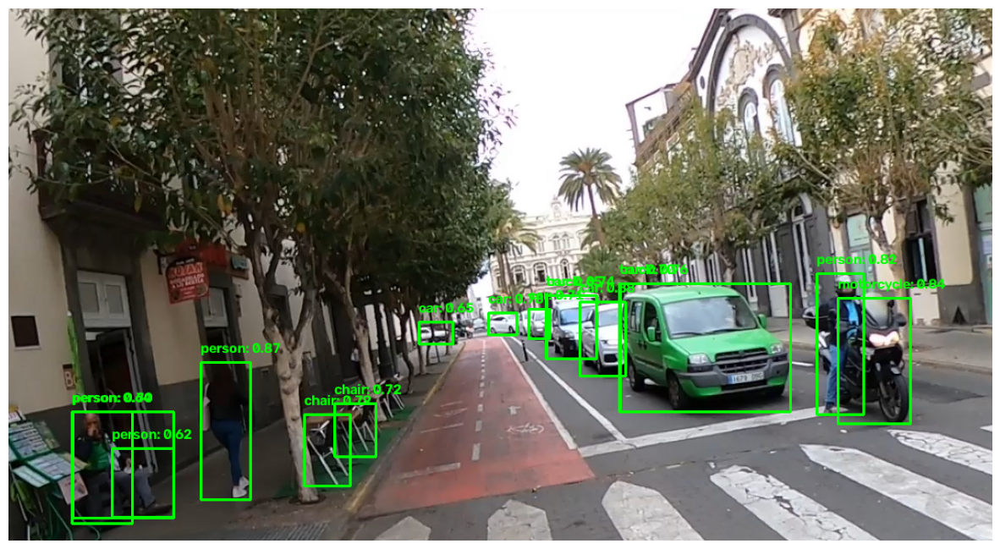

In [3]:
# Ejemplo de uso con imagen estática.

path_test = 'test.jpg'
image = cv2.imread(path_test)

boxes, scores, labels = detect(image, conf=0.6)

for box, score, label in zip(boxes, scores, labels):
    x1, y1, x2, y2 = box.astype(int)
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(image, f"{CLASS_NAMES[label]}: {score:.2f}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    
plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')



In [4]:
# Ejemplo de uso parecido al de YOLO. Detectar entrada desde la webcam.

vid = cv2.VideoCapture('C0142.MP4')
#vid = cv2.VideoCapture(0)
while True:
    ret, img = vid.read()

    if ret:
        boxes, scores, labels = detect(img, conf=0.5)

        for (x1, y1, x2, y2), score, cls in zip(boxes, scores, labels):
            color = tuple(int(c) for c in np.random.RandomState(int(cls)).randint(50, 255, 3))  # BGR
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 3)
            cv2.putText(img, f"{CLASS_NAMES[int(cls)]} {score:.2f}", (int(x1), max(int(y1) - 8, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

        cv2.imshow("Vid", img)
        if cv2.waitKey(20) == 27:
            break

vid.release()
cv2.destroyAllWindows()

## Fase 1. Datos

Preparación del dataset propio de matrículas para entrenar RT-DETR.

- **Origen**: El dataset, sus imagenes y anotaciones. Cada anotación es un JSON con una lista de matrículas: `rectangle` = `[cx, cy, w, h]` normalizado (estilo YOLO) y `plate` = texto (`"None"` si es ilegible).
- **Orientación**: las cajas están anotadas sobre la imagen ya girada según su EXIF (300 fotos tienen orientación 6), así que se aplica la rotación EXIF antes de reescalar.
- **Salida**: `P4\Dataset_coco` con las imágenes reescaladas (lado mayor 1280 px, sin ampliar las pequeñas) y un JSON COCO por conjunto de datos (train, val y test).
- **Una sola clase** (`matricula`, `category_id = 0`, porque RT-DETR usa el id directamente como etiqueta cuando no se remapean las categorías de COCO).
- **Para el OCR** se conservan en cada anotación: `segmentation` (polígono de 4 esquinas derivado de la caja, ya que el dataset no trae polígono), `text` (`None` si es ilegible) y `chars` (lista de caracteres del texto).
- Las matrículas ilegibles cuentan para el detector; para el OCR se descartan (`legible = False`).
- `20261031_174251.jpg` no tiene anotación y se excluye.

In [5]:
import json, random
from pathlib import Path
from collections import Counter
from PIL import Image, ImageOps

#Importante en los directorios no tener el caracter "º", como por ejemplo "4º Curso", da error por la cara

#Directorio del dataset original (En este caso es del drive, con sus respectivas anotaciones)
DATASET_DIR = Path(r"C:/Users/kikoa/OneDrive/Documentos/aa UNIVERSIDAD/VC (Vision por Computador)/P4/dataset")
IMG_DIR     = DATASET_DIR / "images"
ANN_DIR     = DATASET_DIR / "annotations"

#Directorio para guardar imagenes y anotaciones escaladas (Dejar "\P4\Dataset_coco" y cambiar lo anterior)
OUT_DIR     = Path(r"./Dataset_coco/")
OUT_IMG_DIR = OUT_DIR / "images"
OUT_ANN_DIR = OUT_DIR / "annotations"

MAX_SIDE = 1280                                        # lado mayor tras reescalar
BLOCK    = 10                                          # fotos seguidas que van juntas al mismo conjunto
SPLITS   = {"train": 0.60, "val": 0.15, "test": 0.25}
SEED     = 42

CATEGORIES = [{"id": 0, "name": "matricula", "supercategory": "vehiculo"}]
IMG_EXTS   = {".jpg", ".jpeg", ".png"}

### 1. Reescalar y convertir a COCO

In [6]:
import statistics

def rect_to_xyxy(rect, W, H):
    """[cx, cy, w, h] normalizado -> esquinas en píxeles, recortadas a la imagen."""
    cx, cy, w, h = rect
    x1 = max(0.0, (cx - w / 2) * W)
    y1 = max(0.0, (cy - h / 2) * H)
    x2 = min(float(W), (cx + w / 2) * W)
    y2 = min(float(H), (cy + h / 2) * H)
    return x1, y1, x2, y2


def load_resized(path):
    """Abre la imagen, aplica la rotación EXIF y reduce el lado mayor a MAX_SIDE (no amplía)."""
    im = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    W, H = im.size
    scale = min(1.0, MAX_SIDE / max(W, H))
    if scale < 1.0:
        im = im.resize((round(W * scale), round(H * scale)), Image.LANCZOS)
    return im


OUT_IMG_DIR.mkdir(parents=True, exist_ok=True)
OUT_ANN_DIR.mkdir(parents=True, exist_ok=True)

coco_images, coco_anns = [], []
sin_anotacion, cajas_degeneradas = [], 0

img_paths = sorted(p for p in IMG_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
for img_path in img_paths:
    ann_path = ANN_DIR / f"{img_path.stem}.json"
    if not ann_path.exists():
        sin_anotacion.append(img_path.name)
        continue

    out_name = f"{img_path.stem}.jpg"
    out_path = OUT_IMG_DIR / out_name
    if out_path.exists():                       # ya procesada en una ejecución anterior
        W, H = Image.open(out_path).size
    else:
        im = load_resized(img_path)
        im.save(out_path, quality=95)           # se guarda sin EXIF: la orientación ya está aplicada
        W, H = im.size

    img_id = len(coco_images)
    coco_images.append({"id": img_id, "file_name": out_name, "width": W, "height": H,
                        "orig_name": img_path.name})

    objs = json.loads(ann_path.read_text(encoding="utf-8"))
    # Algunas fotos con EXIF de orientación 6 se anotaron sobre la imagen SIN girar: todas sus
    # cajas salen verticales (ancho/alto << 1). Se detectan por la mediana de la proporción y se
    # llevan a la imagen girada (90° horario): cx' = 1 - cy, cy' = cx, ancho y alto intercambiados.
    orient  = Image.open(img_path).getexif().get(0x0112, 1)
    ratios  = [o["rectangle"][2] * W / (o["rectangle"][3] * H) for o in objs if o["rectangle"][2] * o["rectangle"][3] > 0]
    anotacion_girada = orient == 6 and bool(ratios) and statistics.median(ratios) < 0.6

    for obj in objs:
        cx, cy, rw, rh = obj["rectangle"]
        rect = [1 - cy, cx, rh, rw] if anotacion_girada else obj["rectangle"]
        x1, y1, x2, y2 = rect_to_xyxy(rect, W, H)
        w, h = x2 - x1, y2 - y1
        if w < 1 or h < 1:
            cajas_degeneradas += 1
            continue
        plate   = obj.get("plate")
        bbox    = [round(v, 2) for v in (x1, y1, w, h)]
        legible = plate is not None and plate.strip().upper() not in ("", "NONE")   # "None" y "NONE" = ilegible
        text    = plate.strip().upper() if legible else None
        coco_anns.append({
            "id": len(coco_anns),
            "image_id": img_id,
            "category_id": 0,
            "bbox": bbox,
            "area": round(bbox[2] * bbox[3], 2),    # área coherente con la caja redondeada
            "iscrowd": 0,
            "segmentation": [[round(v, 2) for v in (x1, y1, x2, y1, x2, y2, x1, y2)]],
            "text": text,
            "chars": list(text) if legible else [],
            "legible": legible,
            "anotacion_girada": anotacion_girada,
        })

print(f"Imágenes convertidas: {len(coco_images)}")
print(f"Matrículas: {len(coco_anns)}  (legibles: {sum(a['legible'] for a in coco_anns)})")
print(f"Sin anotación (excluidas): {sin_anotacion}")
print(f"Cajas descartadas por tamaño < 1 px: {cajas_degeneradas}")
print("Tamaños más frecuentes:", Counter((i['width'], i['height']) for i in coco_images).most_common(5))

Imágenes convertidas: 2183
Matrículas: 4781  (legibles: 2893)
Sin anotación (excluidas): ['20261031_174251.jpg']
Cajas descartadas por tamaño < 1 px: 124
Tamaños más frecuentes: [((960, 1280), 809), ((1280, 960), 620), ((720, 1280), 385), ((1280, 720), 101), ((958, 1280), 66)]


### 2. División en train, val y test

Las imágenes se ordenan por nombre y se agrupan en bloques de 10 fotos seguidas. Los bloques se barajan con semilla fija y se asignan enteros a cada conjunto (60 % train, 15 % val, 25 % test), de modo que fotos consecutivas del mismo coche no queden repartidas entre conjuntos.

In [7]:
blocks = [coco_images[i:i + BLOCK] for i in range(0, len(coco_images), BLOCK)]
order = list(range(len(blocks)))
random.Random(SEED).shuffle(order)

n_total = len(coco_images)
limits  = {"train": SPLITS["train"] * n_total,
           "val":   (SPLITS["train"] + SPLITS["val"]) * n_total}

split_of_img, assigned = {}, 0
for b in order:
    split = "train" if assigned < limits["train"] else "val" if assigned < limits["val"] else "test"
    for img in blocks[b]:
        split_of_img[img["id"]] = split
    assigned += len(blocks[b])

coco_splits = {}
for split in SPLITS:
    imgs = [i for i in coco_images if split_of_img[i["id"]] == split]
    ids  = {i["id"] for i in imgs}
    anns = [a for a in coco_anns if a["image_id"] in ids]
    coco_splits[split] = {
        "info": {"description": f"Matrículas - {split}", "max_side": MAX_SIDE, "seed": SEED, "block": BLOCK},
        "images": imgs,
        "annotations": anns,
        "categories": CATEGORIES,
    }
    (OUT_ANN_DIR / f"instances_{split}.json").write_text(json.dumps(coco_splits[split], ensure_ascii=False),
                                                         encoding="utf-8")

# Carpeta de imágenes propia para cada conjunto (copias de OUT_IMG_DIR)
import shutil
for split, d in coco_splits.items():
    split_dir = OUT_DIR / f"images_{split}"
    split_dir.mkdir(exist_ok=True)
    for img in d["images"]:
        dst = split_dir / img["file_name"]
        if not dst.exists():
            shutil.copy2(OUT_IMG_DIR / img["file_name"], dst)

# Comprobación: cada bloque cae entero en un único conjunto
assert all(len({split_of_img[i["id"]] for i in blk}) == 1 for blk in blocks)

print(f"{'conjunto':<6} {'imágenes':>9} {'%':>6} {'matrículas':>11} {'legibles':>9}")
for split, d in coco_splits.items():
    n_img = len(d["images"])
    print(f"{split:<6} {n_img:>9} {100 * n_img / n_total:>5.1f}% {len(d['annotations']):>11} "
          f"{sum(a['legible'] for a in d['annotations']):>9}")
print(f"\nJSON guardados en {OUT_ANN_DIR}")

conjunto  imágenes      %  matrículas  legibles
train       1313  60.1%        2864      1769
val          330  15.1%         695       407
test         540  24.7%        1222       717

JSON guardados en Dataset_coco\annotations


### 3. Visualización de anotaciones en train

Caja en verde, polígono en rojo y el texto encima (`?` si la matrícula es ilegible).

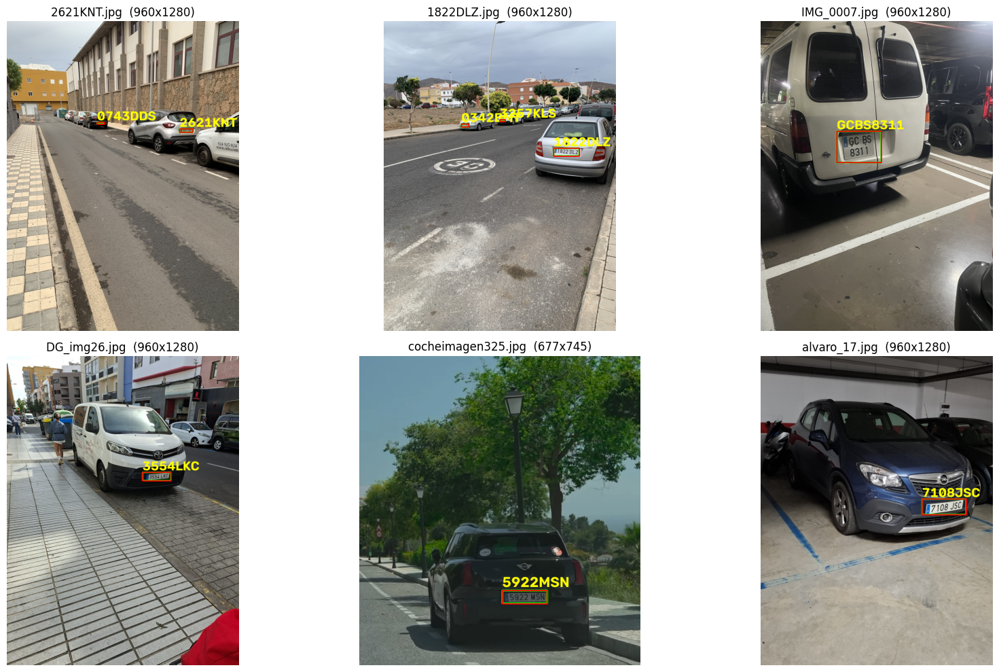

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def draw_annotations(coco, img_info):
    img  = cv2.cvtColor(cv2.imread(str(OUT_IMG_DIR / img_info["file_name"])), cv2.COLOR_BGR2RGB)
    lw   = max(2, round(max(img.shape[:2]) / 400))
    for a in (a for a in coco["annotations"] if a["image_id"] == img_info["id"]):
        x, y, w, h = map(int, a["bbox"])
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), lw + 2)
        poly = np.array(a["segmentation"][0], dtype=np.int32).reshape(-1, 2)
        cv2.polylines(img, [poly], isClosed=True, color=(255, 0, 0), thickness=lw)
        cv2.putText(img, a["text"] or "?", (x, max(y - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX,
                    0.6 * lw, (255, 255, 0), lw)
    return img

train = coco_splits["train"]
con_matricula = sorted({a["image_id"] for a in train["annotations"]})
muestra = random.Random(SEED).sample(con_matricula, 6)
info_by_id = {i["id"]: i for i in train["images"]}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, img_id in zip(axes.ravel(), muestra):
    info = info_by_id[img_id]
    ax.imshow(draw_annotations(train, info))
    ax.set_title(f"{info['file_name']}  ({info['width']}x{info['height']})")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fase 2. Configuración del entrenamiento para el modelo de matrículas

Creada carpeta **config** con los ficheros:
- **coco_detection.yml** -> Establece el nº de clases, directorio de anotaciones e imágenes train y val y el evaluador
- **rtdetrv2_r18vd_120e_coco.yml** -> Características del modelo, nº de epocas, learning rate, data augmentation y entre otros


### Características varias
- Data Augmentation, con `RandomPhotometricDistort`,  `RandomZoomOut`, `RandomZoomIn`, `Resize` y entre otros...
- Exponential Moving Average (EMA) da más prioridad a los pesos actuales y menos a los antiguos
- 50 épocas
- ResNet de 18 capas + 3 capas de decoder. Modelo **RT-DETRV2-S**, con los pesos originales
- Batch de 16 elementos
- Optimizador AdamW
- El nº de clases se ha reducido a 1, sólo matrículas
<br><br>

### Consideración previa a entrenar

Hay que descargarse los pesos base para entrenar, es un fichero .pth que no tenemos. Por ello se debe descargar en el link del [Github](https://github.com/lyuwenyu/storage/releases/download/v0.2/rtdetrv2_r18vd_120e_coco_rerun_48.1.pth) y guardarse en `/weights`
<br><br><br><br>

## Fase 3. Ejecución del entrenamiento

Para llevar a cabo el entrenamiento, se debe ejecutar este comando en el environment de conda:

```bash 
python RT-DETR/rtdetrv2_pytorch/tools/train.py -c configs/rtdetrv2_r18vd_120e_coco.yml --use-amp --seed 0
```

Al usar imágenes de 640x640, con batch de 16 items, y un modelo con 18 capas, tiende a tardar y a consumir mucha VRAM/RAM. En este caso, con la configuración establecida, con 8GB de VRAM, el entrenamiento debería tardar **1-2 horas**☠️
<br><br><br><br>

## Fase 4. Evaluación en test y análisis de errores

Se evalúa `best.pth` (época 47, la mejor en validación) sobre las **300 imágenes de test**, que el modelo no ha visto ni se usaron para elegir la época. Se usan los pesos EMA, como en la validación del entrenamiento.

1. Carga del modelo y comprobación visual de las cajas corregidas.
2. Inferencia sobre test y métricas COCO (las mismas que imprime el repo).
3. Métricas complementarias ignorando las matrículas ilegibles.
4. Emparejamiento detección ↔ matrícula real (IoU ≥ 0.5): aciertos, fallos y falsas detecciones.
5. Visualización de los fallos.

Como comprobación, las métricas oficiales también se pueden obtener con el script del repo (desde `P4`):

```bash
python RT-DETR/rtdetrv2_pytorch/tools/train.py -c configs/rtdetrv2_r18vd_120e_coco.yml -r output/rtdetrv2_r18vd_matriculas/best.pth --test-only -u val_dataloader.dataset.img_folder=C:/Uni/VC/Dataset_coco/images_test val_dataloader.dataset.ann_file=C:/Uni/VC/Dataset_coco/annotations/instances_test.json output_dir=C:/Uni/VC/practicasVC/P4/output/eval_test
```
<br><br><br><br>

### 1. Carga del modelo entrenado

In [9]:
from src.core import YAMLConfig
from src.core.yaml_utils import load_config
from pathlib import Path

#Cambiar directorio, como antes
DATASET_COCO = Path("./Dataset_coco")
TEST_IMG_DIR = DATASET_COCO / "images_test"
TEST_ANN     = DATASET_COCO / "annotations" / "instances_test.json"

CFG_PATH = "configs/rtdetrv2_r18vd_120e_coco.yml"
BEST     = Path("./weights/best2.pth")
OUT_EVAL = Path("output/rtdetrv2_r18vd_matriculas")
OUT_EVAL.mkdir(parents=True, exist_ok=True)

INPUT_SIZE = 800          # resolución de entrada del modelo (eval_spatial_size)

load_config.__defaults__[0].clear()       # evita que se mezclen configs cargados antes en el cuaderno
cfg  = YAMLConfig(CFG_PATH)
ckpt = torch.load(BEST, map_location="cpu", weights_only=False)   # checkpoint propio (incluye estado del optimizador)
cfg.model.load_state_dict(ckpt["ema"]["module"])                  # pesos EMA, los usados en la validación

det_model = cfg.model.deploy().to(DEVICE)
det_post  = cfg.postprocessor.deploy().to(DEVICE)

n_params = sum(p.numel() for p in det_model.parameters())
print(f"best.pth: época {ckpt['last_epoch']}  |  {n_params / 1e6:.1f} M parámetros  |  dispositivo: {DEVICE}")

best.pth: época 46  |  21.8 M parámetros  |  dispositivo: cuda


### 2. Inferencia sobre test y métricas COCO

Mismo preprocesado que la validación del repo: imagen completa redimensionada a 640×640 (bilineal) y escalada a [0, 1]. El postprocesador devuelve las cajas en píxeles de la imagen original (1280 px de lado mayor), igual que las anotaciones.

In [10]:
import time
import contextlib, io
import json
from collections import Counter

coco_gt = json.loads(TEST_ANN.read_text(encoding="utf-8"))

@torch.no_grad()
def predict(img_path):
    im = Image.open(img_path).convert("RGB")
    w, h = im.size
    x = torch.from_numpy(np.asarray(im.resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR)))
    x = x.permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    _, boxes, scores = det_post(det_model(x), torch.tensor([[w, h]], device=DEVICE))
    return boxes[0].cpu().numpy(), scores[0].cpu().numpy()          # xyxy en píxeles, score

results, t0 = [], time.time()
for img in coco_gt["images"]:
    boxes, scores = predict(TEST_IMG_DIR / img["file_name"])
    for (x1, y1, x2, y2), s in zip(boxes, scores):
        results.append({"image_id": img["id"], "category_id": 0,
                        "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)], "score": float(s)})
elapsed = time.time() - t0
print(f"{len(coco_gt['images'])} imágenes en {elapsed:.1f} s ({1000 * elapsed / len(coco_gt['images']):.0f} ms/imagen)")
(OUT_EVAL / "detecciones_test.json").write_text(json.dumps(results), encoding="utf-8")

KeyboardInterrupt: 

In [ ]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def coco_eval(gt_dict, dets, titulo):
    with contextlib.redirect_stdout(io.StringIO()):           # oculta los mensajes internos de pycocotools
        gt = COCO(); gt.dataset = gt_dict; gt.createIndex()
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox"); E.evaluate(); E.accumulate()
    print(f"\n===== {titulo} =====")
    E.summarize()
    return E.stats

stats_test = coco_eval(coco_gt, results, "TEST - todas las matrículas")


===== TEST - todas las matrículas =====
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.480
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.775
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.519
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.357
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.675
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.840
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.309
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.549
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.593
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.493
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.783
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.887

### 3. Métricas ignorando las matrículas ilegibles

Las matrículas con `legible = False` (lejanas, borrosas o tapadas) se marcan como `iscrowd = 1`: si el modelo las detecta no cuenta como error, y si no las detecta tampoco. Así se ve el rendimiento sobre las matrículas que el OCR podría leer. **Es solo un diagnóstico**: no cambia el dataset ni el entrenamiento.

In [11]:
gt_legibles = json.loads(json.dumps(coco_gt))
for a in gt_legibles["annotations"]:
    a["iscrowd"] = 0 if a["legible"] else 1

stats_leg = coco_eval(gt_legibles, results, "TEST - ignorando matrículas ilegibles")

n_leg = sum(a["legible"] for a in coco_gt["annotations"])
print(f"\nMatrículas en test: {len(coco_gt['annotations'])}  (legibles: {n_leg}, ilegibles: {len(coco_gt['annotations']) - n_leg})")
print(f"AP 0.50:0.95  todas: {stats_test[0]:.3f}   solo legibles: {stats_leg[0]:.3f}")
print(f"AP 0.50       todas: {stats_test[1]:.3f}   solo legibles: {stats_leg[1]:.3f}")

NameError: name 'coco_eval' is not defined

### 4. Aciertos, fallos y falsas detecciones

Cada detección con score ≥ umbral se empareja con la matrícula real de mayor IoU (≥ 0.5) que siga libre, empezando por las de mayor score.

- **Acierto (TP)**: detección emparejada con una matrícula.
- **Fallo (FN)**: matrícula sin detección.
- **Falsa detección (FP)**, de tres tipos:
  - *mal ajustada*: solapa con una matrícula (0.1 ≤ IoU < 0.5) pero la caja no encaja;
  - *duplicada*: una matrícula ya detectada se detecta otra vez;
  - *fondo*: no hay ninguna matrícula debajo.

El tamaño se mide como **alto de la matrícula tal como la ve el modelo** (a 640 px), que es lo que realmente determina si se puede detectar.

In [12]:
from collections import defaultdict

def iou_matrix(a, b):
    """IoU entre cajas [x, y, w, h] (a: N, b: M)."""
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    ax2, ay2, bx2, by2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2[:, None], bx2) - np.maximum(a[:, None, 0], b[:, 0]), 0, None)
    ih = np.clip(np.minimum(ay2[:, None], by2) - np.maximum(a[:, None, 1], b[:, 1]), 0, None)
    inter = iw * ih
    return inter / (a[:, 2:].prod(1)[:, None] + b[:, 2:].prod(1) - inter + 1e-9)

img_by_id  = {i["id"]: i for i in coco_gt["images"]}
gts_by_img = defaultdict(list)
for a in coco_gt["annotations"]:
    gts_by_img[a["image_id"]].append(a)
dets_by_img = defaultdict(list)
for d in results:
    dets_by_img[d["image_id"]].append(d)

def emparejar(conf, iou_thr=0.5):
    gt_rows, det_rows = [], []
    for img_id, img in img_by_id.items():
        gts  = gts_by_img[img_id]
        dets = sorted((d for d in dets_by_img[img_id] if d["score"] >= conf), key=lambda d: -d["score"])
        ious = iou_matrix([d["bbox"] for d in dets], [g["bbox"] for g in gts]) if dets and gts else np.zeros((len(dets), len(gts)))
        libre = np.ones(len(gts), bool)
        gt_det = [None] * len(gts)
        for i, d in enumerate(dets):
            cand = np.where(libre & (ious[i] >= iou_thr))[0] if len(gts) else []
            if len(cand):
                j = cand[ious[i, cand].argmax()]
                libre[j] = False; gt_det[j] = (d["score"], ious[i, j])
                tipo = "TP"
            else:
                best = ious[i].max() if len(gts) else 0.0
                tipo = "FP duplicada" if best >= iou_thr else "FP mal ajustada" if best >= 0.1 else "FP fondo"
            det_rows.append({"image_id": img_id, "bbox": d["bbox"], "score": d["score"], "tipo": tipo,
                             "iou_max": float(ious[i].max()) if len(gts) else 0.0})
        escala = INPUT_SIZE / img["height"]
        for g, m in zip(gts, gt_det):
            gt_rows.append({"image_id": img_id, "ann_id": g["id"], "bbox": g["bbox"], "text": g["text"],
                            "legible": g["legible"], "alto_640": g["bbox"][3] * escala,
                            "detectada": m is not None, "score": m[0] if m else None, "iou": m[1] if m else None})
    return gt_rows, det_rows

# Precisión / recall / F1 según el umbral de confianza
print(f"{'umbral':>6} {'TP':>5} {'FP':>5} {'FN':>5} {'precisión':>10} {'recall':>7} {'F1':>6} {'recall legibles':>16}")
tabla = []
for conf in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    g, d = emparejar(conf)
    tp = sum(r["detectada"] for r in g); fp = sum(r["tipo"] != "TP" for r in d); fn = len(g) - tp
    p, r = tp / max(tp + fp, 1), tp / max(len(g), 1)
    f1 = 2 * p * r / max(p + r, 1e-9)
    leg = [x for x in g if x["legible"]]
    r_leg = sum(x["detectada"] for x in leg) / max(len(leg), 1)
    tabla.append((conf, f1))
    print(f"{conf:>6.1f} {tp:>5} {fp:>5} {fn:>5} {p:>10.3f} {r:>7.3f} {f1:>6.3f} {r_leg:>16.3f}")

CONF = max(tabla, key=lambda t: t[1])[0]
print(f"\nUmbral usado para el análisis: {CONF} (mejor F1)")

umbral    TP    FP    FN  precisión  recall     F1  recall legibles
   0.2   760   997   462      0.433   0.622  0.510            0.782
   0.3   737   400   485      0.648   0.603  0.625            0.778
   0.4   713   192   509      0.788   0.583  0.670            0.778
   0.5   684    95   538      0.878   0.560  0.684            0.774
   0.6   643    60   579      0.915   0.526  0.668            0.763
   0.7   586    39   636      0.938   0.480  0.635            0.742

Umbral usado para el análisis: 0.5 (mejor F1)


In [13]:
import csv

gt_rows, det_rows = emparejar(CONF)

# Recall según el alto de la matrícula a 640 px y su legibilidad
bins   = [0, 4, 8, 16, 32, 1e9]
labels = ["< 4 px", "4-8 px", "8-16 px", "16-32 px", "> 32 px"]
print(f"Recall por alto de la matrícula a {INPUT_SIZE} px (umbral {CONF})\n")
print(f"{'alto':>9} | {'legibles':>18} | {'ilegibles':>18}")
for lo, hi, lab in zip(bins[:-1], bins[1:], labels):
    celdas = []
    for leg in (True, False):
        grupo = [r for r in gt_rows if r["legible"] == leg and lo <= r["alto_640"] < hi]
        det = sum(r["detectada"] for r in grupo)
        celdas.append(f"{det:>3}/{len(grupo):<3} ({100 * det / len(grupo):5.1f} %)" if grupo else f"{'-':>18}")
    print(f"{lab:>9} | {celdas[0]:>18} | {celdas[1]:>18}")

print("\nFalsas detecciones por tipo:", dict(Counter(r["tipo"] for r in det_rows if r["tipo"] != "TP")))
ious_tp = [r["iou"] for r in gt_rows if r["detectada"]]
print(f"IoU de los aciertos: mediana {np.median(ious_tp):.2f}  |  con IoU ≥ 0.75: {100 * np.mean(np.array(ious_tp) >= 0.75):.1f} %")

# Se guardan para poder analizarlos después
with open(OUT_EVAL / "analisis_gt.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(gt_rows[0].keys())); w.writeheader(); w.writerows(gt_rows)
with open(OUT_EVAL / "analisis_det.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(det_rows[0].keys())); w.writeheader(); w.writerows(det_rows)
print(f"\nGuardado en {OUT_EVAL}")

Recall por alto de la matrícula a 800 px (umbral 0.5)

     alto |           legibles |          ilegibles
   < 4 px |   12/23  ( 52.2 %) |   40/295 ( 13.6 %)
   4-8 px |   78/138 ( 56.5 %) |   46/131 ( 35.1 %)
  8-16 px |  155/215 ( 72.1 %) |   32/65  ( 49.2 %)
 16-32 px |  183/212 ( 86.3 %) |   10/11  ( 90.9 %)
  > 32 px |  127/129 ( 98.4 %) |    1/3   ( 33.3 %)

Falsas detecciones por tipo: {'FP mal ajustada': 43, 'FP fondo': 50, 'FP duplicada': 2}
IoU de los aciertos: mediana 0.85  |  con IoU ≥ 0.75: 77.3 %

Guardado en output\rtdetrv2_r18vd_matriculas


### 5. Visualización de los fallos

- **Matrículas legibles no detectadas**, de mayor a menor (las grandes son los fallos más llamativos). Se muestra un recorte ampliado alrededor de cada una, con la caja real en rojo.
- **Imágenes completas** con más fallos: caja real detectada en verde, no detectada en rojo, falsas detecciones en magenta con su score.
- **Falsas detecciones de fondo** con mayor score: qué confunde el modelo con una matrícula.

Matrículas legibles no detectadas: 162 de 717


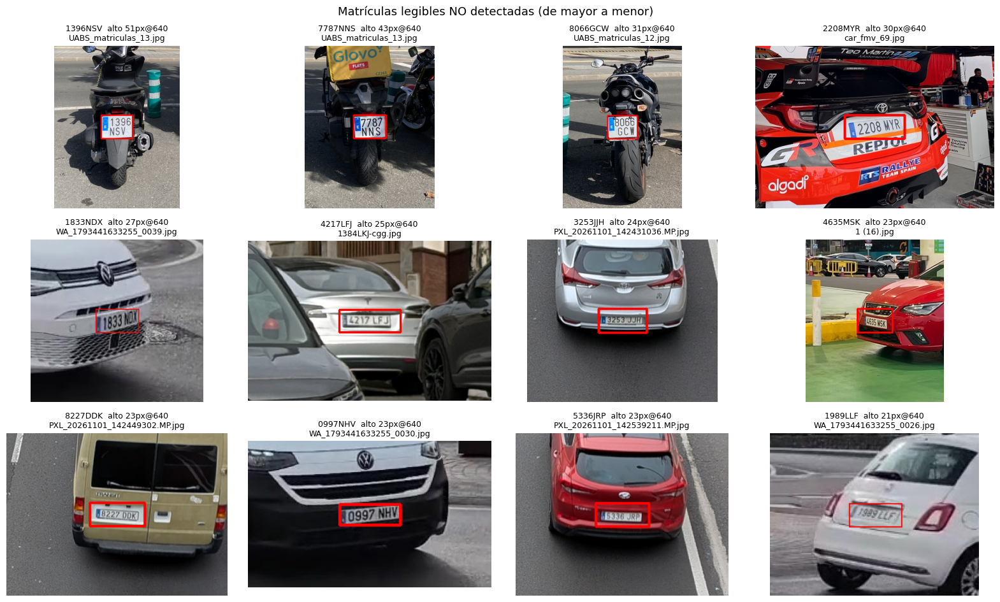

In [14]:
def cargar(img_id):
    return cv2.cvtColor(cv2.imread(str(TEST_IMG_DIR / img_by_id[img_id]["file_name"])), cv2.COLOR_BGR2RGB)

def recorte(img, bbox, margen=1.5, min_lado=80):
    """Recorte alrededor de la caja con margen proporcional; devuelve la imagen y la caja relativa."""
    x, y, w, h = bbox
    cx, cy = x + w / 2, y + h / 2
    lado_w, lado_h = max(w * (1 + 2 * margen), min_lado), max(h * (1 + 2 * margen * 2), min_lado / 2)
    H, W = img.shape[:2]
    x1, y1 = int(np.clip(cx - lado_w / 2, 0, W - 2)), int(np.clip(cy - lado_h / 2, 0, H - 2))
    x2, y2 = int(np.clip(cx + lado_w / 2, x1 + 2, W)), int(np.clip(cy + lado_h / 2, y1 + 2, H))
    return np.ascontiguousarray(img[y1:y2, x1:x2]), (x - x1, y - y1, w, h)

def mostrar_recortes(filas, titulo, color, n=12, info=None):
    filas = filas[:n]
    if not filas:
        print(f"{titulo}: ninguno"); return
    cols = 4; nrows = int(np.ceil(len(filas) / cols))
    fig, axes = plt.subplots(nrows, cols, figsize=(16, 3.2 * nrows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, r in zip(axes.ravel(), filas):
        crop, (x, y, w, h) = recorte(cargar(r["image_id"]), r["bbox"])
        lw = max(1, round(max(crop.shape[:2]) / 150))
        cv2.rectangle(crop, (int(x), int(y)), (int(x + w), int(y + h)), color, lw)
        ax.imshow(crop)
        ax.set_title(info(r), fontsize=9)
    fig.suptitle(titulo, fontsize=13); plt.tight_layout(); plt.show()

nombre = lambda r: img_by_id[r["image_id"]]["file_name"]

fallos_leg = sorted((r for r in gt_rows if r["legible"] and not r["detectada"]), key=lambda r: -r["alto_640"])
print(f"Matrículas legibles no detectadas: {len(fallos_leg)} de {sum(r['legible'] for r in gt_rows)}")
mostrar_recortes(fallos_leg, "Matrículas legibles NO detectadas (de mayor a menor)", (255, 0, 0),
                 info=lambda r: f"{r['text']}  alto {r['alto_640']:.0f}px@640\n{nombre(r)}")

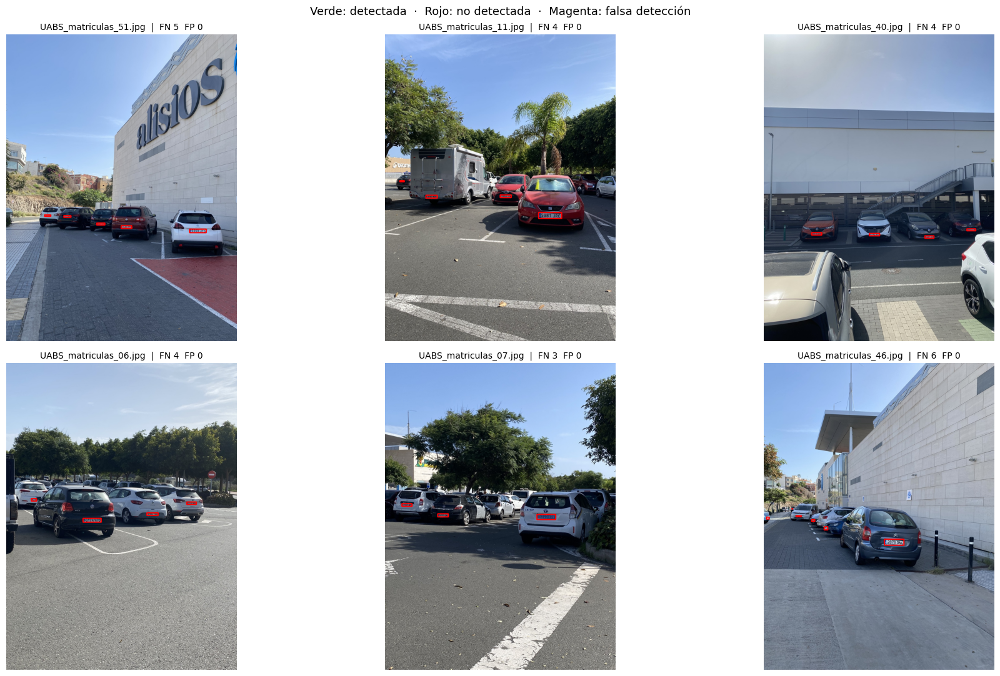

In [15]:
def dibujar_imagen(img_id, ax):
    img = cargar(img_id)
    lw = max(2, round(max(img.shape[:2]) / 400))
    for r in (r for r in gt_rows if r["image_id"] == img_id):
        x, y, w, h = map(int, r["bbox"])
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 200, 0) if r["detectada"] else (255, 0, 0), lw)
    for r in (r for r in det_rows if r["image_id"] == img_id and r["tipo"] != "TP"):
        x, y, w, h = map(int, r["bbox"])
        cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 255), lw)
        cv2.putText(img, f"{r['score']:.2f}", (x, max(y - 6, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.5 * lw, (255, 0, 255), lw)
    ax.imshow(img); ax.axis("off")
    n_fn = sum(1 for r in gt_rows if r["image_id"] == img_id and not r["detectada"])
    n_fp = sum(1 for r in det_rows if r["image_id"] == img_id and r["tipo"] != "TP")
    ax.set_title(f"{img_by_id[img_id]['file_name']}  |  FN {n_fn}  FP {n_fp}", fontsize=10)

# Imágenes con más matrículas legibles sin detectar (desempate: más falsas detecciones)
peso = Counter(r["image_id"] for r in fallos_leg)
fp_img = Counter(r["image_id"] for r in det_rows if r["tipo"] != "TP")
peores = sorted(set(peso) | set(fp_img), key=lambda i: (-peso[i], -fp_img[i]))[:6]

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax in axes.ravel(): ax.axis("off")
for ax, img_id in zip(axes.ravel(), peores):
    dibujar_imagen(img_id, ax)
fig.suptitle("Verde: detectada  ·  Rojo: no detectada  ·  Magenta: falsa detección", fontsize=13)
plt.tight_layout(); plt.show()

Falsas detecciones de fondo: 50


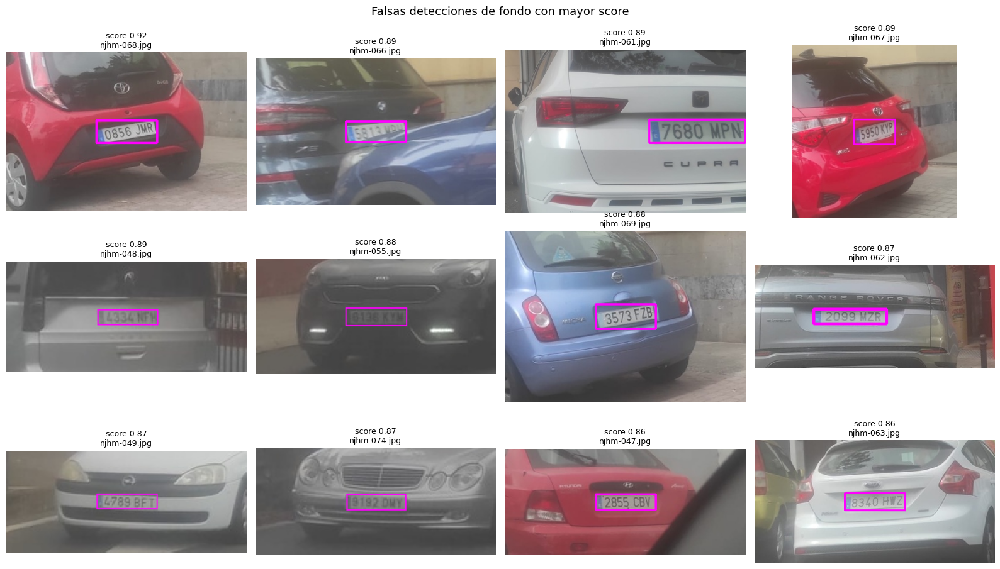

Falsas detecciones mal ajustadas: 43


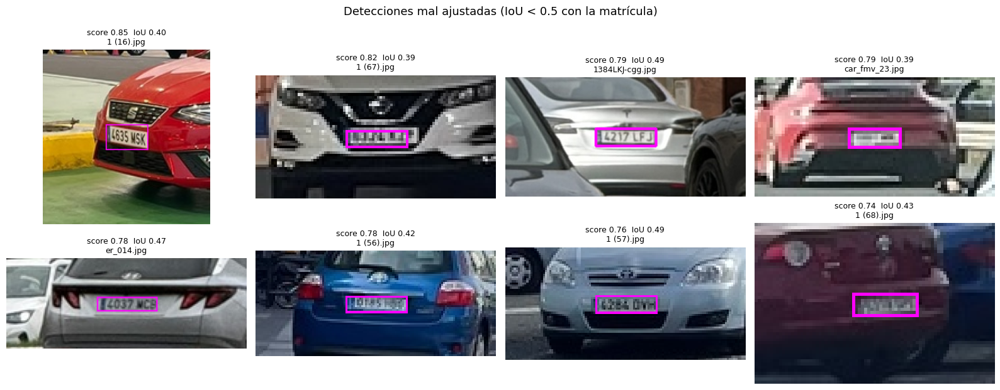

In [16]:
fp_fondo = sorted((r for r in det_rows if r["tipo"] == "FP fondo"), key=lambda r: -r["score"])
print(f"Falsas detecciones de fondo: {len(fp_fondo)}")
mostrar_recortes(fp_fondo, "Falsas detecciones de fondo con mayor score", (255, 0, 255),
                 info=lambda r: f"score {r['score']:.2f}\n{nombre(r)}")

fp_ajuste = sorted((r for r in det_rows if r["tipo"] == "FP mal ajustada"), key=lambda r: -r["score"])
print(f"Falsas detecciones mal ajustadas: {len(fp_ajuste)}")
mostrar_recortes(fp_ajuste, "Detecciones mal ajustadas (IoU < 0.5 con la matrícula)", (255, 0, 255), n=8,
                 info=lambda r: f"score {r['score']:.2f}  IoU {r['iou_max']:.2f}\n{nombre(r)}")

## Fase 5. Modelo funcionando sobre un video

- Instalar módulos `trackers` (ya incluye el supervision)
- Ejecutar la primera celda antes que nada 

In [17]:
from pathlib import Path
from src.core import YAMLConfig
from src.core.yaml_utils import load_config
#from trackers import ByteTrackTracker
import supervision as sv

#Pasa de tensor de Torch a numpy array (requerido por supervision)
def a_numpy(x):
    if isinstance(x, torch.Tensor):
        return x.detach().cpu().numpy()
    return np.asarray(x)

CFG = Path("configs/rtdetrv2_r18vd_120e_coco.yml")  # la configuración usada al entrenar
CFG_BASE = Path("RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r50vd_6x_coco.yml")
BEST = Path("weights/best2.pth")                   # ajusta si best.pth está en otra carpeta
BASE = Path("weights/rtdetrv2_r50vd_6x_coco_ema.pth")

if not BEST.is_file():
    raise FileNotFoundError(f"No se encontró el checkpoint: {BEST.resolve()}")

# Evita que configuraciones de celdas ejecutadas antes se mezclen.
load_config.__defaults__[0].clear()
cfg = YAMLConfig(CFG)
cfg_base = YAMLConfig(CFG_BASE)

ckpt = torch.load(BEST, map_location="cuda", weights_only=False)
ckpt_base = torch.load(BASE, map_location="cuda", weights_only=False)

state_dict = ckpt["ema"]["module"] if "ema" in ckpt else ckpt["model"]
state_dict_base = ckpt_base["ema"]["module"] if "ema" in ckpt_base else ckpt_base["model"]

cfg.model.load_state_dict(state_dict)
cfg_base.model.load_state_dict(state_dict_base)

model = cfg.model.deploy().to(DEVICE)
model_base = cfg_base.model.deploy().to(DEVICE)
postprocessor = cfg.postprocessor.deploy().to(DEVICE)            # 1 clase, 100 queries
postprocessor_base = cfg_base.postprocessor.deploy().to(DEVICE)  # 80 clases COCO, 300 queries


#Tracker para el modelo base

#tracker = ByteTrackTracker()
tracker = sv.ByteTrack()

box_base = sv.BoxAnnotator(color=sv.Color.GREEN)
label_base = sv.LabelAnnotator(color=sv.Color.GREEN, text_color=sv.Color.BLACK)
trace_base = sv.TraceAnnotator(color=sv.Color.GREEN)

#Detección con anotadores de sv
box_extra = sv.BoxAnnotator(color=sv.Color.RED)
label_extra = sv.LabelAnnotator(color=sv.Color.RED, text_color=sv.Color.WHITE)

@torch.no_grad()
def detect(model, postprocessor, bgr, size, conf=0.6):
    # size debe coincidir con el eval_spatial_size con el que se construyó el modelo
    
    h, w = bgr.shape[:2]
    im = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).resize((size, size), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    labels, boxes, scores = postprocessor(model(x), torch.tensor([[w, h]], device=DEVICE))
    labels, boxes, scores = labels[0].cpu().numpy(), boxes[0].cpu().numpy(), scores[0].cpu().numpy()
    keep = scores >= conf  
    return boxes[keep], scores[keep], labels[keep]

def fraction_plate(box_plate, box_car):
    """Fracción del área de la matrícula que cae dentro del coche. Cajas en formato xyxy en píxeles."""
    x1, y1 = max(box_plate[0], box_car[0]), max(box_plate[1], box_car[1])
    x2, y2 = min(box_plate[2], box_car[2]), min(box_plate[3], box_car[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_plate = max(0.0, box_plate[2] - box_plate[0]) * max(0.0, box_plate[3] - box_plate[1])
    return inter / area_plate if area_plate > 0 else 0.0

def plate_in_car(box_plate, box_car, umbral=0.9):
    # Se tolera que la matrícula sobresalga un poco de la caja del coche (umbral < 1)
    return fraction_plate(box_plate, box_car) >= umbral

def assign_plate_to_car(boxes_plate, boxes_car, umbral=0.9):
    """Devuelve, para cada matrícula, el índice del coche que la contiene (o -1 si ninguno).
    Si varios coches la contienen (solapados), se elige el de menor área: el más cercano a la matrícula."""
    asignaciones = []
    for bp in boxes_plate:
        mejor, mejor_area = -1, np.inf
        for j, bc in enumerate(boxes_car):
            area = (bc[2] - bc[0]) * (bc[3] - bc[1])
            if plate_in_car(bp, bc, umbral) and area < mejor_area:
                mejor, mejor_area = j, area
        asignaciones.append(mejor)
    return asignaciones


Load PResNet50 state_dict


In [18]:

# El modelo y la función detect() deben estar cargados antes de ejecutar esta celda.

PLATE_CLASS = {0: "Matrícula"}
CLASS_NAMES_BASE = {lab: mscoco_category2name[cat] for lab, cat in mscoco_label2category.items()}
# Clases COCO consideradas vehículo (índices contiguos 0-79, como los devuelve el postprocesador en modo deploy)
VEHICULOS = {lab for lab, nombre in CLASS_NAMES_BASE.items() if nombre in ("car", "motorcycle", "bus", "truck")}
video_path = "C0142.mp4"
vid = cv2.VideoCapture(video_path)

if not vid.isOpened():
    raise FileNotFoundError(f"No se pudo abrir el vídeo: {video_path}")

try:

    with open("output/detecciones_test.csv", "w", encoding="utf-8") as cvs:
        cvs.write("frame, clase_vehiculo, confianza, id_tracker, x1_vehiculo, y1_vehiculo, x2_vehiculo, y2_vehiculo, is_plate, x1_matricula, y1_matricula, x2_matricula, y2_matricula\n")

        while True:
            ret, img = vid.read()
            if not ret:
                break
            num_frame = int(vid.get(cv2.CAP_PROP_POS_FRAMES))

            #Detección de vehículos con el modelo base
            boxes, scores, labels = detect(model_base, postprocessor_base, img, size=640, conf=0.5)

            if len(boxes) > 0:
                detections = sv.Detections(
                    xyxy=a_numpy(boxes).astype(np.float32),
                    confidence=a_numpy(scores).astype(np.float32),
                    class_id=a_numpy(labels).astype(int),
                )
            else:
                detections = sv.Detections.empty()

            #Actualiza el tracker con las detecciones de vehículos
            
            #tracked = tracker.update(detections)
            tracked = tracker.update_with_detections(detections)

            class_id = None

            #Etiquetado para el modelo base: clase y confianza, con el id de tracker
            etiquetas_base = [
                f"#{tid} {CLASS_NAMES_BASE.get(int(cid), f'Clase {int(cid)}')} {conf:.2f}"
                for tid, cid, conf in zip(
                    tracked.tracker_id, tracked.class_id, tracked.confidence
                )
            ]

            #Detección de matrículas con el modelo entrenado
            boxes_plate, scores_plate, labels_plate = detect(model, postprocessor, img, size=800, conf=0.35)
            if len(boxes_plate) > 0:
                plate_detections = sv.Detections(
                    xyxy=a_numpy(boxes_plate).astype(np.float32),
                    confidence=a_numpy(scores_plate).astype(np.float32),
                    class_id=a_numpy(labels_plate).astype(int),
                )
            else:
                plate_detections = sv.Detections.empty()

            # Relaciona cada matrícula con el vehículo seguido que la contiene
            idx_vehiculos = np.flatnonzero(np.isin(tracked.class_id, list(VEHICULOS)))
            asignaciones = assign_plate_to_car(plate_detections.xyxy, tracked.xyxy[idx_vehiculos])
            matricula_de = {}  # tracker_id del vehículo -> caja de su matrícula
            for k, j in enumerate(asignaciones):
                if j >= 0:
                    matricula_de[int(tracked.tracker_id[idx_vehiculos[j]])] = plate_detections.xyxy[k]

            #Etiquetado de las matrículas: clase y confianza, y si se ha asignado a un vehículo, su id de tracker
            etiquetas_extra = [
                f"{PLATE_CLASS.get(int(cid), f'Clase {int(cid)}')} {conf:.2f}"
                + (f" -> #{tracked.tracker_id[idx_vehiculos[j]]}" if j >= 0 else "")
                for cid, conf, j in zip(plate_detections.class_id, plate_detections.confidence, asignaciones)
            ]


            #Muestreo de las detecciones y seguimiento de vehículos y matrículas en la imagen
            img = box_base.annotate(scene=img, detections=tracked)
            img = label_base.annotate(scene=img, detections=tracked, labels=etiquetas_base)

            img = box_extra.annotate(scene=img, detections=plate_detections)
            img = label_extra.annotate(scene=img, detections=plate_detections, labels=etiquetas_extra)

            # Una fila por vehículo; cajas en formato xyxy (píxeles). Sin matrícula, sus columnas quedan vacías
            for j in idx_vehiculos:
                tid = int(tracked.tracker_id[j])
                nombre = CLASS_NAMES_BASE.get(int(tracked.class_id[j]), f"Clase {int(tracked.class_id[j])}")
                caja_vehiculo = ", ".join(f"{v:.0f}" for v in tracked.xyxy[j])
                caja = matricula_de.get(tid)
                is_plate = "Matrícula Detectada" if caja is not None else "Matrícula NO Detectada"
                caja_matricula = ", ".join(f"{v:.0f}" for v in caja) if caja is not None else ", , ,"
                cvs.write(f"{num_frame}, {nombre}, {tracked.confidence[j]:.2f}, {tid}, {caja_vehiculo}, {is_plate}, {caja_matricula}\n")

            cv2.imshow("Detección de matrículas", img)
            if cv2.waitKey(1) & 0xFF == 27:  # Esc para salir
                break
finally:
    vid.release()
    cv2.destroyAllWindows()

# Fase 6. OCR de matrículas con Florence-2 base

Flujo: **RT-DETR** detecta la matrícula → se recorta la caja → **Florence-2** (`<OCR>`) lee el texto.

- Se usa la implementación nativa de `transformers` (`florence-community/Florence-2-base`, **sin** `trust_remote_code`). Requiere `transformers >= 4.56`:
  `pip install -U "transformers>=4.56"`
- El modelo de OCR se llama `ocr_model` (no `model`) para no pisar el detector de matrículas, que en el cuaderno usa `model` y `postprocessor`.
- Esta sección necesita que ya estén definidos `DEVICE` y `detect()` (celdas anteriores).

In [20]:
import re, difflib
import cv2
import numpy as np
import torch
from PIL import Image
from transformers import AutoProcessor, Florence2ForConditionalGeneration

OCR_MODEL_ID = "florence-community/Florence-2-base"

OCR_DTYPE    = torch.float16 if DEVICE.type == "cuda" else torch.float32

ocr_processor = AutoProcessor.from_pretrained(OCR_MODEL_ID)
ocr_model = Florence2ForConditionalGeneration.from_pretrained(OCR_MODEL_ID, dtype=OCR_DTYPE).to(DEVICE).eval()

print(f"Florence-2 base: {sum(p.numel() for p in ocr_model.parameters()) / 1e6:.0f} M parámetros en {DEVICE} ({OCR_DTYPE})")

Florence-2 base: 231 M parámetros en cuda (torch.float16)


### 1. Funciones de OCR

- `crop_plate`: recorta la caja del detector con un pequeño margen.
- `to_square`: Florence-2 redimensiona **siempre a 768×768**. Una matrícula es muy apaisada (~4.7:1), así que se rellena hasta un cuadrado (gris) en lugar de deformarla.
- `clean_plate` / `fix_plate`: limpieza del texto. `fix_plate` es opcional y solo actúa sobre el formato actual español (`1234 BCD`: 4 dígitos + 3 letras, sin vocales ni Q), corrigiendo confusiones típicas por posición (O↔0, B↔8, S↔5…).
- `read_plates`: OCR por lotes de una lista de recortes.

In [21]:
PLATE_MODERN = re.compile(r"^\d{4}[BCDFGHJKLMNPRSTVWXYZ]{3}$")
TO_DIGIT  = {"O": "0", "Q": "0", "D": "0", "I": "1", "L": "1", "Z": "2", "S": "5", "B": "8", "G": "6"}
TO_LETTER = {"0": "D", "2": "Z", "5": "S", "8": "B", "6": "G"}


def crop_plate(bgr, box, margin=0.08):
    """Recorta la caja xyxy (píxeles) con un margen proporcional. None si queda degenerada."""
    H, W = bgr.shape[:2]
    x1, y1, x2, y2 = box
    mx, my = (x2 - x1) * margin, (y2 - y1) * margin
    x1, y1 = int(max(0, x1 - mx)), int(max(0, y1 - my))
    x2, y2 = int(min(W, x2 + mx)), int(min(H, y2 + my))
    if x2 - x1 < 2 or y2 - y1 < 2:
        return None
    return bgr[y1:y2, x1:x2]


def to_square(bgr, fill=114):
    """Rellena el recorte hasta un cuadrado (sin deformar) y lo pasa a PIL RGB."""
    h, w = bgr.shape[:2]
    s = max(h, w)
    top, left = (s - h) // 2, (s - w) // 2
    sq = cv2.copyMakeBorder(bgr, top, s - h - top, left, s - w - left,
                            cv2.BORDER_CONSTANT, value=(fill, fill, fill))
    return Image.fromarray(cv2.cvtColor(sq, cv2.COLOR_BGR2RGB))


def clean_plate(text):
    return re.sub(r"[^A-Z0-9]", "", text.upper())


def fix_plate(text):
    """Corrige confusiones número/letra si el texto tiene 7 caracteres (formato actual).
    Si tras corregir no encaja con el formato, devuelve el texto sin tocar."""
    if len(text) != 7:
        return text
    fixed = "".join(TO_DIGIT.get(c, c) for c in text[:4]) + "".join(TO_LETTER.get(c, c) for c in text[4:])
    return fixed if PLATE_MODERN.match(fixed) else text


@torch.no_grad()
def read_plates(crops_bgr, batch_size=16, num_beams=3, fix=True):
    """OCR de una lista de recortes BGR. Devuelve una lista de str (misma longitud)."""
    texts = []
    for i in range(0, len(crops_bgr), batch_size):
        imgs = [to_square(c) for c in crops_bgr[i:i + batch_size]]
        inputs = ocr_processor(text=["<OCR>"] * len(imgs), images=imgs, return_tensors="pt").to(DEVICE, OCR_DTYPE)
        ids = ocr_model.generate(**inputs, max_new_tokens=20, num_beams=num_beams, do_sample=False)
        out = ocr_processor.batch_decode(ids, skip_special_tokens=True)
        texts += [fix_plate(clean_plate(t)) if fix else clean_plate(t) for t in out]
    return texts


def ocr_frame(bgr, boxes):
    """Detecciones (xyxy) -> lista de (cx, cy, texto) para una imagen."""
    crops = [(b, crop_plate(bgr, b)) for b in boxes]
    crops = [(b, c) for b, c in crops if c is not None]
    if not crops:
        return []
    texts = read_plates([c for _, c in crops])
    return [((b[0] + b[2]) / 2, (b[1] + b[3]) / 2, t) for (b, _), t in zip(crops, texts)]

### 2. Prueba con una imagen estática

5923KVP    score detección 0.91
LC8NOL     score detección 0.81


(np.float64(-0.5), np.float64(959.5), np.float64(1279.5), np.float64(-0.5))

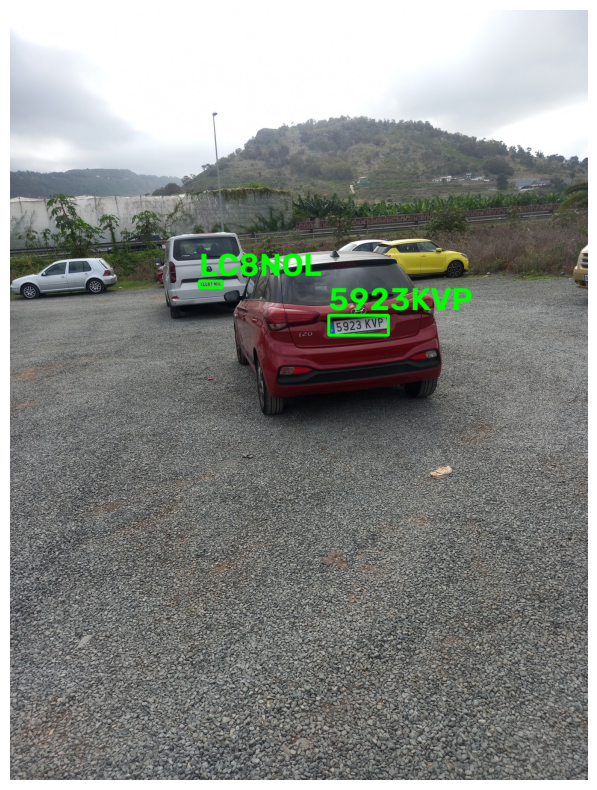

In [22]:
import random
import matplotlib.pyplot as plt

# TEST_IMG_DIR debe apuntar a Dataset_coco/images_test
extensiones = {".jpg", ".jpeg", ".png", ".bmp"}
imagenes = [
    p for p in TEST_IMG_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensiones
]

image_path = random.choice(imagenes)
image = cv2.imread(str(image_path))

# tratamos la imagen con el modelo RT-DERT
boxes, scores, _ = detect(model, postprocessor, image, size=800, conf=0.5)

# pasamos la imagen por el el OCR
resultados = ocr_frame(image, boxes)

vis = image.copy()
lw = max(2, round(max(vis.shape[:2]) / 400))
for (x1, y1, x2, y2), s, (_, _, texto) in zip(boxes.astype(int), scores, resultados):
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), lw)
    cv2.putText(vis, texto, (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * lw, (0, 255, 0), lw)
    print(f"{texto or '(vacío)':<10} score detección {s:.2f}")

plt.figure(figsize=(15, 10)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")

### 3. Evaluación del OCR sobre test (aislada del detector)

Se recorta con la **caja real** de cada matrícula legible de test y se compara con el texto anotado (`text`). Así se mide solo el OCR, sin mezclar los fallos del detector.

- **Exact match**: la matrícula completa coincide.
- **Similitud media**: proporción de caracteres coincidentes (`difflib`), da idea de cuánto se acerca cuando falla.

Se evalúa con y sin `fix_plate` para ver si la corrección por posición ayuda realmente en vuestro dataset (puede haber matrículas antiguas o extranjeras que no sigan el formato).

In [ ]:
from collections import defaultdict

def eval_ocr(coco_gt, img_dir, fix=True, max_imgs=None):
    anns_by_img = defaultdict(list)
    for a in coco_gt["annotations"]:
        if a["legible"]:
            anns_by_img[a["image_id"]].append(a)
    img_info = {i["id"]: i for i in coco_gt["images"]}
    ids = list(anns_by_img)[:max_imgs]

    filas = []
    for img_id in ids:
        bgr = cv2.imread(str(img_dir / img_info[img_id]["file_name"]))
        anns, crops = [], []
        for a in anns_by_img[img_id]:
            x, y, w, h = a["bbox"]
            c = crop_plate(bgr, (x, y, x + w, y + h))
            if c is not None:
                anns.append(a); crops.append(c)
        for a, pred in zip(anns, read_plates(crops, fix=fix)):
            filas.append((img_info[img_id]["file_name"], a["text"], pred))

    exact = np.mean([gt == pr for _, gt, pr in filas])
    sim   = np.mean([difflib.SequenceMatcher(None, gt, pr).ratio() for _, gt, pr in filas])
    return filas, exact, sim

for fix in (False, True):
    filas, exact, sim = eval_ocr(coco_gt, TEST_IMG_DIR, fix=fix)
    print(f"fix_plate={fix!s:<5} | {len(filas)} matrículas | exact match {100 * exact:.1f} % | similitud media {sim:.3f}")

print("\nErrores (real -> predicho):")
for nombre, gt, pr in [f for f in filas if f[1] != f[2]][:20]:
    print(f"  {gt:<9} -> {pr or '(vacío)':<9} {nombre}")

fix_plate=False | 717 matrículas | exact match 38.6 % | similitud media 0.714
fix_plate=True  | 717 matrículas | exact match 40.3 % | similitud media 0.719

Errores (real -> predicho):
  0951MVN   -> E0951MVN  09d2d922-35f1-4ed3-93a5-82a1ed54d8cb.jpg
  6324KZP   -> 6974KZP   1 (1).jpg
  4610FNP   -> 6510FN    1 (10).jpg
  4721LJT   -> 67211JT   1 (11).jpg
  4721LJT   -> 1721LJT   1 (12).jpg
  4170KDX   -> E4170KDX  1 (13).jpg
  2062MTM   -> 2062WIM   1 (14).jpg
  8838LKV   -> 1300LKV   1 (14).jpg
  1137MDN   -> 1170      1 (53).jpg
  6591LXG   -> 13591LXG  1 (55).jpg
  0185HBG   -> 1         1 (55).jpg
  0185HBG   -> LORAS     1 (56).jpg
  7737JKT   -> 17737JKY  1 (57).jpg
  4284DVH   -> 1622OYH   1 (57).jpg
  6022CBW   -> 62220     1 (59).jpg
  0718KDL   -> 0718KOL   1 (6).jpg
  5076JWJ   -> SATSLB    1 (60).jpg
  5925KYW   -> 5925KYT   1 (61).jpg
  1423FFC   -> UL23FFC   1 (62).jpg
  2508HHK   -> 2RADIC    1 (62).jpg


### 4. Detección + OCR sobre vídeo

El OCR es bastante más caro que el detector, así que solo se ejecuta cada `OCR_EVERY` fotogramas. En los fotogramas intermedios cada caja reutiliza el texto de la lectura anterior más cercana (por centro de caja), sin necesidad de tracking.

Nota: `cv2.putText` no pinta tildes (`í` sale como `?`), por eso la etiqueta es solo el texto de la matrícula.

In [23]:
def lectura_cercana(cache, box):
    """Texto de la lectura cuyo centro está más cerca de la caja (si está dentro de ~1 ancho de caja)."""
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    ancho = box[2] - box[0]
    mejor = min(cache, key=lambda c: (c[0] - cx) ** 2 + (c[1] - cy) ** 2, default=None)
    if mejor is None or np.hypot(mejor[0] - cx, mejor[1] - cy) > ancho:
        return ""
    conf_ocr = float(mejor[3]) if len(mejor) > 3 else None
    return mejor[2], conf_ocr


def limpiar_texto(t):
    """Normaliza la lectura: mayúsculas y solo caracteres alfanuméricos (evita comas que rompan el CSV)."""
    return re.sub(r"[^A-Z0-9]", "", str(t).upper())


# Lecturas acumuladas por vehículo: tracker_id -> Counter({texto: votos})
lecturas = defaultdict(Counter)

def texto_vehiculo(tid):
    """Lectura más votada para ese vehículo ('' si aún no hay ninguna)."""
    c = lecturas.get(tid)
    return c.most_common(1)[0][0] if c else ""

# Confianzas por vehículo y texto: tracker_id -> {texto: [conf, conf, ...]}
confianzas = defaultdict(lambda: defaultdict(list))

def conf_vehiculo(tid):
    """Confianza media de las lecturas que coinciden con el texto ganador ('' si no hay lectura)."""
    texto = texto_vehiculo(tid)
    if not texto:
        return ""
    valores = confianzas[tid][texto]
    return f"{sum(valores) / len(valores):.2f}"

def etiqueta_lectura(tid):
    """'1234ABC (0.87)' si el vehículo tiene lectura, '' si no."""
    texto = texto_vehiculo(tid)
    return f"{texto} ({conf_vehiculo(tid)})" if texto else ""

In [24]:
# El modelo, detect(), assign_plate_to_car() y ocr_frame() deben estar cargados antes de ejecutar esta celda.
from collections import defaultdict, Counter
import re

OCR_EVERY = 5
OCR_CONF = 0.6


PLATE_CLASS = {0: "Matrícula"}
CLASS_NAMES_BASE = {lab: mscoco_category2name[cat] for lab, cat in mscoco_label2category.items()}
VEHICULOS = {lab for lab, nombre in CLASS_NAMES_BASE.items() if nombre in ("car", "motorcycle", "bus", "truck")}

video_path = "C0142.mp4"
vid = cv2.VideoCapture(video_path)
if not vid.isOpened():
    raise FileNotFoundError(f"No se pudo abrir el vídeo: {video_path}")

frame_idx = 0
try:
    with open("output/detecciones_test.csv", "w", encoding="utf-8") as cvs:
        cvs.write("frame,clase_vehiculo,confianza,id_tracker,x1_vehiculo,y1_vehiculo,x2_vehiculo,y2_vehiculo,"
          "is_plate,x1_matricula,y1_matricula,x2_matricula,y2_matricula,texto_matricula,confianza_matricula\n")

        while True:
            ret, img = vid.read()
            if not ret:
                break
            num_frame = int(vid.get(cv2.CAP_PROP_POS_FRAMES))

            # --- Detección y seguimiento de vehículos ---
            boxes, scores, labels = detect(model_base, postprocessor_base, img, size=640, conf=0.5)
            if len(boxes) > 0:
                detections = sv.Detections(
                    xyxy=a_numpy(boxes).astype(np.float32),
                    confidence=a_numpy(scores).astype(np.float32),
                    class_id=a_numpy(labels).astype(int),
                )
            else:
                detections = sv.Detections.empty()
            tracked = tracker.update_with_detections(detections)

            # --- Detección de matrículas ---
            boxes_plate, scores_plate, labels_plate = detect(model, postprocessor, img, size=800, conf=0.35)
            if len(boxes_plate) > 0:
                plate_detections = sv.Detections(
                    xyxy=a_numpy(boxes_plate).astype(np.float32),
                    confidence=a_numpy(scores_plate).astype(np.float32),
                    class_id=a_numpy(labels_plate).astype(int),
                )
            else:
                plate_detections = sv.Detections.empty()

            # --- Asignación matrícula -> vehículo ---
            idx_vehiculos = np.flatnonzero(np.isin(tracked.class_id, list(VEHICULOS)))
            asignaciones = assign_plate_to_car(plate_detections.xyxy, tracked.xyxy[idx_vehiculos])
            matricula_de = {}  # tracker_id del vehículo -> caja de su matrícula
            tid_de_placa = []  # tracker_id asignado a cada matrícula (None si no tiene)
            for k, j in enumerate(asignaciones):
                if j >= 0:
                    tid = int(tracked.tracker_id[idx_vehiculos[j]])
                    matricula_de[tid] = plate_detections.xyxy[k]
                    tid_de_placa.append(tid)
                else:
                    tid_de_placa.append(None)

            # --- OCR cada OCR_EVERY frames, solo sobre matrículas con confianza > OCR_CONF ---
            if frame_idx % OCR_EVERY == 0 and len(plate_detections) > 0:
                idx_ocr = [
                    k for k, (conf, tid) in enumerate(zip(plate_detections.confidence, tid_de_placa))
                    if conf > OCR_CONF and tid is not None
                ]

                if idx_ocr:
                    cache = ocr_frame(img, plate_detections.xyxy[idx_ocr])
                    for k in idx_ocr:
                        texto, conf_ocr = lectura_cercana(cache, plate_detections.xyxy[k])
                        texto = limpiar_texto(texto)
                        if texto:
                            # Confianza del OCR si existe; si no, la de la detección de la matrícula
                            conf = conf_ocr if conf_ocr is not None else float(plate_detections.confidence[k])
                            tid = tid_de_placa[k]
                            lecturas[tid][texto] += 1
                            confianzas[tid][texto].append(conf)

            # --- Etiquetas ---
            def etiqueta_lectura(tid):
                """'1234ABC (0.87)' si el vehículo tiene lectura, '' si no."""
                texto = texto_vehiculo(tid)
                return f"{texto} ({conf_vehiculo(tid)})" if texto else ""

            # Vehículos: #id clase conf  [+ matrícula leída]
            etiquetas_base = []
            for tid, cid, conf in zip(tracked.tracker_id, tracked.class_id, tracked.confidence):
                etiqueta = f"#{tid} {CLASS_NAMES_BASE.get(int(cid), f'Clase {int(cid)}')} {conf:.2f}"
                lectura = etiqueta_lectura(int(tid))
                if lectura:
                    etiqueta += f" | {lectura}"
                etiquetas_base.append(etiqueta)

            # Matrículas: [lectura] Matricula conf -> #id
            etiquetas_extra = []
            for cid, conf, tid in zip(plate_detections.class_id, plate_detections.confidence, tid_de_placa):
                etiqueta = f"{PLATE_CLASS.get(int(cid), f'Clase {int(cid)}')} {conf:.2f}"
                if tid is not None:
                    lectura = etiqueta_lectura(tid)
                    etiqueta = (f"{lectura} " if lectura else "") + etiqueta + f" -> #{tid}"
                etiquetas_extra.append(etiqueta)

            # --- Anotación ---
            img = box_base.annotate(scene=img, detections=tracked)
            img = label_base.annotate(scene=img, detections=tracked, labels=etiquetas_base)
            img = box_extra.annotate(scene=img, detections=plate_detections)
            img = label_extra.annotate(scene=img, detections=plate_detections, labels=etiquetas_extra)

            # --- CSV: una fila por vehículo ---
            for j in idx_vehiculos:
                tid = int(tracked.tracker_id[j])
                nombre = CLASS_NAMES_BASE.get(int(tracked.class_id[j]), f"Clase {int(tracked.class_id[j])}")
                caja_vehiculo = ",".join(f"{v:.0f}" for v in tracked.xyxy[j])
                caja = matricula_de.get(tid)
                texto = texto_vehiculo(tid)       # '' si todavía no se ha conseguido leer
                conf_texto = conf_vehiculo(tid)   # '' si no hay lectura
                
                if caja is None:
                    is_plate = "Matrícula NO Detectada"
                elif texto:
                    is_plate = "Matrícula Leída"
                else:
                    is_plate = "Matrícula Detectada (sin lectura)"

                caja_matricula = ",".join(f"{v:.0f}" for v in caja) if caja is not None else ",,,"
                cvs.write(f"{num_frame},{nombre},{tracked.confidence[j]:.2f},{tid},{caja_vehiculo},"
                        f"{is_plate},{caja_matricula},{texto},{conf_texto}\n")

            cv2.imshow("Detección + OCR de matrículas", img)
            if cv2.waitKey(1) & 0xFF == 27:  # Esc para salir
                break
            frame_idx += 1
finally:
    vid.release()
    cv2.destroyAllWindows()

# Fase 7. easyOCR para detección de matrículas

In [88]:
import re, difflib
import cv2
import numpy as np
import torch
from PIL import Image
import easyocr
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Configurar si EasyOCR usará GPU basándose en el DEVICE existente
use_gpu = DEVICE.type == "cuda"
print(f"Dispositivo detectado para EasyOCR: {'GPU' if use_gpu else 'CPU'}")

# Inicializar el lector de EasyOCR para español
print("Cargando modelo EasyOCR...")
reader = easyocr.Reader(['es'], gpu=use_gpu)

print("EasyOCR cargado exitosamente.")

Dispositivo detectado para EasyOCR: GPU
Cargando modelo EasyOCR...
EasyOCR cargado exitosamente.


In [89]:
def read_plates(crops_bgr, fix=True):
    """OCR de una lista de recortes BGR usando EasyOCR. Devuelve una lista de str."""
    texts = []
    for crop in crops_bgr:
        # Pasamos a RGB ya que EasyOCR procesa muy bien en este formato
        rgb_crop = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
        
        # detail=0 devuelve solo el texto detectado como lista de strings
        # allowlist restringe los caracteres posibles a letras y números (muy útil para matrículas)
        res = reader.readtext(
            rgb_crop, 
            detail=0, 
            allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
        )
        
        # Unimos los fragmentos si EasyOCR los detecta separados
        raw_text = "".join(res) if res else ""
        
        cleaned = clean_plate(raw_text)
        final_text = fix_plate(cleaned) if fix else cleaned
        texts.append(final_text)
        
    return texts

## 1. Prueba de easyOCR con una imagen aleatoria

KYP59501   score detección 0.89


(np.float64(-0.5), np.float64(957.5), np.float64(1279.5), np.float64(-0.5))

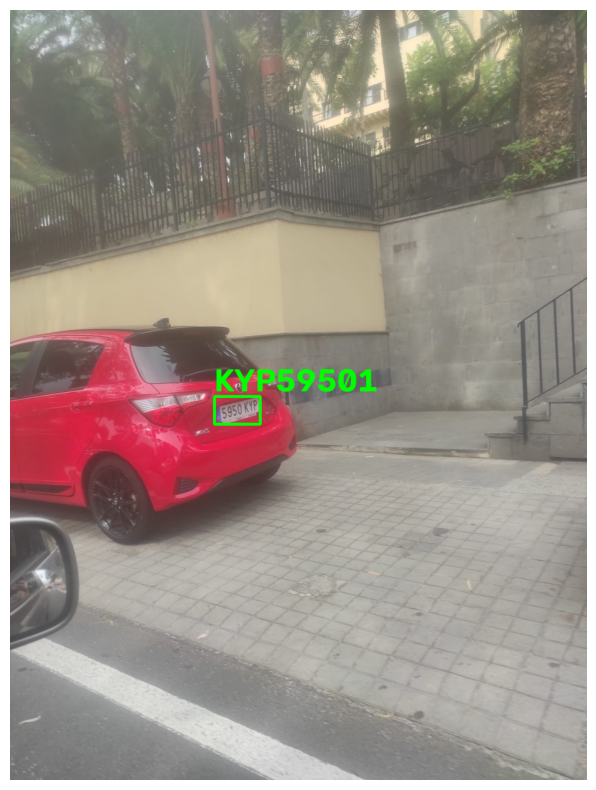

In [90]:
# TEST_IMG_DIR debe apuntar a Dataset_coco/images_test
extensiones = {".jpg", ".jpeg", ".png", ".bmp"}
imagenes = [
    p for p in TEST_IMG_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensiones
]

image_path = random.choice(imagenes)
image = cv2.imread(str(image_path))

# Tratamos la imagen con el modelo RT-DETR
boxes, scores, _ = detect(model, postprocessor, image, size=800, conf=0.5)

# Pasamos la imagen por el OCR de EasyOCR
resultados = ocr_frame(image, boxes)

vis = image.copy()
lw = max(2, round(max(vis.shape[:2]) / 400))
for (x1, y1, x2, y2), s, (_, _, texto) in zip(boxes.astype(int), scores, resultados):
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), lw)
    cv2.putText(vis, texto, (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * lw, (0, 255, 0), lw)
    print(f"{texto or '(vacío)':<10} score detección {s:.2f}")

plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.axis("off")

In [32]:
from collections import defaultdict

def eval_ocr(coco_gt, img_dir, fix=True, max_imgs=None):
    anns_by_img = defaultdict(list)
    for a in coco_gt["annotations"]:
        if a["legible"]:
            anns_by_img[a["image_id"]].append(a)
    img_info = {i["id"]: i for i in coco_gt["images"]}
    ids = list(anns_by_img)[:max_imgs]

    filas = []
    for img_id in ids:
        bgr = cv2.imread(str(img_dir / img_info[img_id]["file_name"]))
        anns, crops = [], []
        for a in anns_by_img[img_id]:
            x, y, w, h = a["bbox"]
            c = crop_plate(bgr, (x, y, x + w, y + h))
            if c is not None:
                anns.append(a); crops.append(c)
        for a, pred in zip(anns, read_plates(crops, fix=fix)):
            filas.append((img_info[img_id]["file_name"], a["text"], pred))

    exact = np.mean([gt == pr for _, gt, pr in filas])
    sim   = np.mean([difflib.SequenceMatcher(None, gt, pr).ratio() for _, gt, pr in filas])
    return filas, exact, sim

for fix in (False, True):
    filas, exact, sim = eval_ocr(coco_gt, TEST_IMG_DIR, fix=fix)
    print(f"fix_plate={fix!s:<5} | {len(filas)} matrículas | exact match {100 * exact:.1f} % | similitud media {sim:.3f}")

print("\nErrores (real -> predicho):")
for nombre, gt, pr in [f for f in filas if f[1] != f[2]][:20]:
    print(f"  {gt:<9} -> {pr or '(vacío)':<9} {nombre}")

fix_plate=False | 717 matrículas | exact match 21.3 % | similitud media 0.474
fix_plate=True  | 717 matrículas | exact match 21.5 % | similitud media 0.475

Errores (real -> predicho):
  0951MVN   -> E0951MVN  09d2d922-35f1-4ed3-93a5-82a1ed54d8cb.jpg
  6324KZP   -> (vacío)   1 (1).jpg
  4610FNP   -> (vacío)   1 (10).jpg
  4721LJT   -> (vacío)   1 (11).jpg
  4721LJT   -> L72ILI    1 (12).jpg
  4170KDX   -> KDX4170   1 (13).jpg
  2062MTM   -> (vacío)   1 (14).jpg
  8838LKV   -> (vacío)   1 (14).jpg
  2783LXF   -> 2783      1 (15).jpg
  4635MSK   -> (vacío)   1 (16).jpg
  1137MDN   -> (vacío)   1 (53).jpg
  6591LXG   -> B9147E    1 (55).jpg
  0185HBG   -> (vacío)   1 (55).jpg
  0185HBG   -> (vacío)   1 (56).jpg
  0643DZG   -> 40620026  1 (57).jpg
  7737JKT   -> (vacío)   1 (57).jpg
  4284DVH   -> (vacío)   1 (57).jpg
  8991NRY   -> 899NRY    1 (58).jpg
  2508HHK   -> 12508HHK  1 (59).jpg
  6022CBW   -> (vacío)   1 (59).jpg


## 2. Ejecución sobre un video de easyOCR

In [91]:
def lectura_cercana(cache, box):
    """Texto de la lectura cuyo centro está más cerca de la caja (si está dentro de ~1 ancho de caja)."""
    cx, cy = (box[0] + box[2]) / 2, (box[1] + box[3]) / 2
    ancho = box[2] - box[0]
    mejor = min(cache, key=lambda c: (c[0] - cx) ** 2 + (c[1] - cy) ** 2, default=None)
    if mejor is None or np.hypot(mejor[0] - cx, mejor[1] - cy) > ancho:
        return "", None
    conf_ocr = float(mejor[3]) if len(mejor) > 3 else None
    return mejor[2], conf_ocr

def limpiar_texto(t):
    """Normaliza la lectura: mayúsculas y solo caracteres alfanuméricos."""
    return re.sub(r"[^A-Z0-9]", "", str(t).upper())

lecturas = defaultdict(Counter)
confianzas = defaultdict(lambda: defaultdict(list))

def texto_vehiculo(tid):
    c = lecturas.get(tid)
    return c.most_common(1)[0][0] if c else ""

def conf_vehiculo(tid):
    texto = texto_vehiculo(tid)
    if not texto:
        return ""
    valores = confianzas[tid][texto]
    return f"{sum(valores) / len(valores):.2f}" if valores else "0.00"

In [92]:
# El modelo, detect(), assign_plate_to_car(), reader y ocr_frame() deben estar cargados antes de ejecutar esta celda.
from collections import defaultdict, Counter
import re
import cv2
import numpy as np
import supervision as sv

OCR_EVERY = 1  # Modificado a 1 para leer en cada fotograma
OCR_CONF = 0.6
GUARDAR_VIDEO = True

PLATE_CLASS = {0: "Matrícula"}
CLASS_NAMES_BASE = {lab: mscoco_category2name[cat] for lab, cat in mscoco_label2category.items()}
VEHICULOS = {lab for lab, nombre in CLASS_NAMES_BASE.items() if nombre in ("car", "motorcycle", "bus", "truck")}

video_path = "C0142.mp4"
vid = cv2.VideoCapture(video_path)
if not vid.isOpened():
    raise FileNotFoundError(f"No se pudo abrir el vídeo: {video_path}")

writer = None
if GUARDAR_VIDEO:
    fps = vid.get(cv2.CAP_PROP_FPS) or 25
    W, H = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH)), int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))
    writer = cv2.VideoWriter("output/video_ocr.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

frame_idx = 0
try:
    with open("output/detecciones_test.csv", "w", encoding="utf-8") as cvs:
        cvs.write("frame,clase_vehiculo,confianza,id_tracker,x1_vehiculo,y1_vehiculo,x2_vehiculo,y2_vehiculo,"
          "is_plate,x1_matricula,y1_matricula,x2_matricula,y2_matricula,texto_matricula,confianza_matricula\n")

        while True:
            ret, img = vid.read()
            if not ret:
                break
            num_frame = int(vid.get(cv2.CAP_PROP_POS_FRAMES))

            # --- Detección y seguimiento de vehículos ---
            boxes, scores, labels = detect(model_base, postprocessor_base, img, size=640, conf=0.5)
            if len(boxes) > 0:
                detections = sv.Detections(
                    xyxy=a_numpy(boxes).astype(np.float32),
                    confidence=a_numpy(scores).astype(np.float32),
                    class_id=a_numpy(labels).astype(int),
                )
            else:
                detections = sv.Detections.empty()
            tracked = tracker.update_with_detections(detections)

            # --- Detección de matrículas ---
            boxes_plate, scores_plate, labels_plate = detect(model, postprocessor, img, size=800, conf=0.35)
            if len(boxes_plate) > 0:
                plate_detections = sv.Detections(
                    xyxy=a_numpy(boxes_plate).astype(np.float32),
                    confidence=a_numpy(scores_plate).astype(np.float32),
                    class_id=a_numpy(labels_plate).astype(int),
                )
            else:
                plate_detections = sv.Detections.empty()

            # --- Asignación matrícula -> vehículo ---
            idx_vehiculos = np.flatnonzero(np.isin(tracked.class_id, list(VEHICULOS)))
            asignaciones = assign_plate_to_car(plate_detections.xyxy, tracked.xyxy[idx_vehiculos])
            matricula_de = {}  
            tid_de_placa = []  
            for k, j in enumerate(asignaciones):
                if j >= 0:
                    tid = int(tracked.tracker_id[idx_vehiculos[j]])
                    matricula_de[tid] = plate_detections.xyxy[k]
                    tid_de_placa.append(tid)
                else:
                    tid_de_placa.append(None)

            # --- OCR en cada frame (OCR_EVERY = 1) con EasyOCR ---
            if frame_idx % OCR_EVERY == 0 and len(plate_detections) > 0:
                idx_ocr = [
                    k for k, (conf, tid) in enumerate(zip(plate_detections.confidence, tid_de_placa))
                    if conf > OCR_CONF and tid is not None
                ]

                if idx_ocr:
                    cache = ocr_frame(img, plate_detections.xyxy[idx_ocr])
                    for k in idx_ocr:
                        texto, conf_ocr = lectura_cercana(cache, plate_detections.xyxy[k])
                        texto = limpiar_texto(texto)
                        if texto:
                            conf = conf_ocr if conf_ocr is not None else float(plate_detections.confidence[k])
                            tid = tid_de_placa[k]
                            lecturas[tid][texto] += 1
                            confianzas[tid][texto].append(conf)

            # --- Etiquetas ---
            def etiqueta_lectura(tid):
                texto = texto_vehiculo(tid)
                return f"{texto} ({conf_vehiculo(tid)})" if texto else ""

            etiquetas_base = []
            for tid, cid, conf in zip(tracked.tracker_id, tracked.class_id, tracked.confidence):
                etiqueta = f"#{tid} {CLASS_NAMES_BASE.get(int(cid), f'Clase {int(cid)}')} {conf:.2f}"
                lectura = etiqueta_lectura(int(tid))
                if lectura:
                    etiqueta += f" | {lectura}"
                etiquetas_base.append(etiqueta)

            etiquetas_extra = []
            for cid, conf, tid in zip(plate_detections.class_id, plate_detections.confidence, tid_de_placa):
                etiqueta = f"{PLATE_CLASS.get(int(cid), f'Clase {int(cid)}')} {conf:.2f}"
                if tid is not None:
                    lectura = etiqueta_lectura(tid)
                    etiqueta = (f"{lectura} " if lectura else "") + etiqueta + f" -> #{tid}"
                etiquetas_extra.append(etiqueta)

            # --- Anotación ---
            img = box_base.annotate(scene=img, detections=tracked)
            img = label_base.annotate(scene=img, detections=tracked, labels=etiquetas_base)
            img = box_extra.annotate(scene=img, detections=plate_detections)
            img = label_extra.annotate(scene=img, detections=plate_detections, labels=etiquetas_extra)

            # --- Guardar fotograma en el vídeo de salida ---
            if writer is not None:
                writer.write(img)

            # --- CSV ---
            for j in idx_vehiculos:
                tid = int(tracked.tracker_id[j])
                nombre = CLASS_NAMES_BASE.get(int(tracked.class_id[j]), f"Clase {int(tracked.class_id[j])}")
                caja_vehiculo = ",".join(f"{v:.0f}" for v in tracked.xyxy[j])
                caja = matricula_de.get(tid)
                texto = texto_vehiculo(tid)       
                conf_texto = conf_vehiculo(tid)   
                
                if caja is None:
                    is_plate = "Matrícula NO Detectada"
                elif texto:
                    is_plate = "Matrícula Leída"
                else:
                    is_plate = "Matrícula Detectada (sin lectura)"

                caja_matricula = ",".join(f"{v:.0f}" for v in caja) if caja is not None else ",,,"
                cvs.write(f"{num_frame},{nombre},{tracked.confidence[j]:.2f},{tid},{caja_vehiculo},"
                        f"{is_plate},{caja_matricula},{texto},{conf_texto}\n")

            cv2.imshow("Detección + OCR de matrículas (EasyOCR)", img)
            if cv2.waitKey(1) & 0xFF == 27:  
                break
            frame_idx += 1
finally:
    vid.release()
    if writer is not None:
        writer.release()
    cv2.destroyAllWindows()

# 8. Tesseract

In [94]:
import cv2
import pytesseract
from pytesseract import Output
import matplotlib.pyplot as plt
import matplotlib.patches as patches



# Si la ruta de Tesseract no está en el PATH, ruta al ejecutable
pytesseract.pytesseract.tesseract_cmd = r'C:/Users/kikoa/Downloads/tesseract/tesseract'

# Lenguajes disponibles
print(pytesseract.get_languages(config=''))

['eng', 'osd']


In [101]:
ALLOWED = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"   # todas, por el formato antiguo
CONFIG = (f"--oem 1 --psm 7 -c tessedit_char_whitelist={ALLOWED} "
          "-c load_system_dawg=0 -c load_freq_dawg=0")

NEW_RE = re.compile(r"^\d{4}[BCDFGHJKLMNPRSTVWXYZ]{3}$")   # 1234 ABC
OLD_RE = re.compile(r"^[A-Z]{1,2}\d{4}[A-Z]{1,2}$")        # GC1234CH

TO_DIGIT  = {"O": "0", "Q": "0", "D": "0", "I": "1", "L": "1",
             "Z": "2", "S": "5", "G": "6", "B": "8"}
TO_LETTER = {"0": "D", "1": "L", "2": "Z", "5": "S", "6": "G", "8": "B"}

def _map(s, table):
    return "".join(table.get(c, c) for c in s)

def smart_fix(text):
    """Corrige confusiones letra/número según la posición, sin forzar un formato."""
    if NEW_RE.match(text) or OLD_RE.match(text):
        return text
    if len(text) == 7:                                     # formato nuevo
        cand = _map(text[:4], TO_DIGIT) + _map(text[4:], TO_LETTER)
        if NEW_RE.match(cand):
            return cand
    for a in (1, 2):                                       # formato antiguo
        for b in (1, 2):
            if a + 4 + b == len(text):
                cand = (_map(text[:a], TO_LETTER) +
                        _map(text[a:a+4], TO_DIGIT) +
                        _map(text[a+4:], TO_LETTER))
                if OLD_RE.match(cand):
                    return cand
    return text                                            # si no encaja, lo deja como está

def read_plates(crops_bgr, fix=True, debug=False):
    texts = []
    for crop in crops_bgr:
        if crop is None or crop.size == 0:
            texts.append("")
            continue
        cands = [_ocr(v) for v in _variants(crop)]
        if fix:
            cands = [(smart_fix(t), c) for t, c in cands]
        if debug:
            print(cands)
        valid = [c for c in cands if NEW_RE.match(c[0]) or OLD_RE.match(c[0])]
        pool = valid or [c for c in cands if c[0]]
        texts.append(max(pool, key=lambda c: c[1])[0] if pool else "")
    return texts

D5826Y     score detección 0.84
LC6087F    score detección 0.79
TYYY2      score detección 0.58


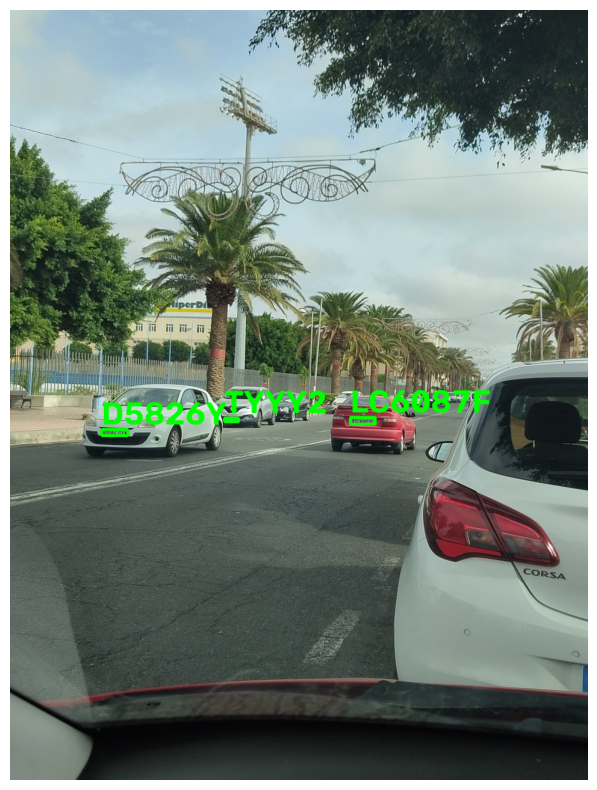

In [105]:
# TEST_IMG_DIR debe apuntar a Dataset_coco/images_test
extensiones = {".jpg", ".jpeg", ".png", ".bmp"}
imagenes = [
    p for p in TEST_IMG_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in extensiones
]

image_path = random.choice(imagenes)
image = cv2.imread(str(image_path))

# Tratamos la imagen con el modelo RT-DETR de matrículas (tamaño 800)
boxes, scores, _ = detect(model, postprocessor, image, size=800, conf=0.5)

# Extraemos los recortes de las matrículas detectadas usando crop_plate
crops = [crop_plate(image, box) for box in boxes]

# Pasamos los recortes por el OCR de Tesseract
textos_leidos = read_plates(crops, fix=True)

vis = image.copy()
lw = max(2, round(max(vis.shape[:2]) / 400))

for (x1, y1, x2, y2), s, texto in zip(boxes.astype(int), scores, textos_leidos):
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), lw)
    cv2.putText(vis, texto, (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * lw, (0, 255, 0), lw)
    print(f"{texto or '(vacío)':<10} score detección {s:.2f}")

plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# MIS COSAS DE LOS OCR

# Fase 6. Comparativa entre Florence-2 base y EasyOCR

Flujo: **RT-DETR** detecta la matrícula → se recorta la caja con margen → (`<OCR>`) lee el texto →
se extrae una matrícula del formato actual español (`1234 BCD`).

Para esta práctica se compararán 2 OCR diferentes, el primero es un OCR basado en tecnologías de VLM, **Florence 2 base**, y el segundo, es un OCR clásico basado en redes neuronales clásicas, **EasyOCR**

## 1. Florence 2 base para la lectura de matrículas

- Implementación nativa de `transformers` (`florence-community/Florence-2-base`, **sin** `trust_remote_code`).
  Requiere `transformers >= 4.56`: `pip install -U "transformers>=4.56"`.
- El OCR se llama `ocr_model` para no pisar los detectores (`model_base`, `model_mat`).
- **Extracción del formato** `1234 BCD` dentro del texto leído (quita la `E` de la franja azul, `FLEXICAR`, dígitos
  de más…) y corrección número↔letra eligiendo la ventana con **menos correcciones**. Si no aparece una matrícula
  válida, la lectura se **descarta**.
- **Confianza del OCR**: probabilidad media por token de la secuencia generada.
- Los recortes se hacen de la **foto original** cuando existe (más resolución en matrículas pequeñas).

La primera versión (recorte con margen del 8 %, sin extracción del formato) acertaba el **43.8 %** de las matrículas
legibles de test con la caja real; se ha sustituido por esta.

In [ ]:
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"      # evita el error de OpenMP duplicado (torch + cv2) en Windows
from pathlib import Path
assert Path("RT-DETR").exists(), "Falta el repositorio de RT-DETR: ejecuta antes la configuración de la Fase 0"
sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))   # módulos src.core, src.data... del repo
import random
import cv2
import torch
import matplotlib.pyplot as plt
from transformers import AutoProcessor, Florence2ForConditionalGeneration

import importlib, utils
importlib.reload(utils)        # recarga utils.py por si se ha modificado, sin reiniciar el kernel
from utils import (MARGEN, PREP_MODE, detect, cargar_detector_matriculas, extraer_matricula, crop_plate_v2,
                   read_plates_v2, recoger, eval_ocr_v2, resumen, por_alto)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CFG_MAT  = Path("configs/rtdetrv2_r18vd_120e_coco.yml")    # detector de matrículas (para la prueba 6.2)
BEST_MAT = Path("weights/best.pth")

# --- Datos para el OCR ---
DATASET_COCO = Path("./Dataset_coco")
TEST_IMG_DIR = DATASET_COCO / "images_test"
# Las matrículas se recortan de las fotos ORIGINALES (sin reescalar a 1280) cuando existen: el coste del OCR
# no cambia (Florence-2 siempre redimensiona a 768x768) y las matrículas pequeñas ganan resolución real.
ORIG_DIRS     = [Path(r"C:/Uni/VC/Dataset/images")]   # carpetas donde buscar orig_name (en orden)
USAR_ORIGINAL = True     # False: recortar de Dataset_coco (1280 px)
ALTO_MAX_OCR  = 64       # alto máx. (px) de la matrícula guardada en caché; más no aporta

# --- OCR ---
OCR_MODEL_ID = "florence-community/Florence-2-base"   # implementación nativa de transformers (>= 4.56)
OCR_DTYPE    = torch.float16 if DEVICE.type == "cuda" else torch.float32
FT_DIR       = Path("weights/florence2_matriculas")    # Florence-2 afinado (Fase 7)
# MARGEN y PREP_MODE (recorte para el OCR) se definen solo en utils.py (valores elegidos en 6.3)

# Argumentos comunes de recoger(): recoger("val", **DATOS_OCR)
DATOS_OCR = dict(dataset_coco=DATASET_COCO, orig_dirs=ORIG_DIRS, usar_original=USAR_ORIGINAL, alto_max=ALTO_MAX_OCR)

In [ ]:
ocr_processor = AutoProcessor.from_pretrained(OCR_MODEL_ID)
ocr_model = Florence2ForConditionalGeneration.from_pretrained(OCR_MODEL_ID, dtype=OCR_DTYPE).to(DEVICE).eval()
model_mat, postprocessor_mat, _ = cargar_detector_matriculas(CFG_MAT, BEST_MAT, DEVICE)
print(f"Florence-2 base: {sum(p.numel() for p in ocr_model.parameters()) / 1e6:.0f} M parámetros en {DEVICE} ({OCR_DTYPE})")

# Comprobación rápida de la extracción del formato con lecturas reales que fallaban
for t in ["E1685MBY", "19908KFK", "E4774JFWFLEXICAR", "IS172JYF", "6000KK", "RANILES", "7653LOS"]:
    print(f"{t:<18} -> {extraer_matricula(t) or '(descartada)'}")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Florence-2 base: 231 M parámetros en cuda (torch.float16)
E1685MBY           -> 1685MBY
19908KFK           -> 9908KFK
E4774JFWFLEXICAR   -> 4774JFW
IS172JYF           -> 5172JYF
6000KK             -> (descartada)
RANILES            -> (descartada)
7653LOS            -> 7653LDS


### 6.1.2 Prueba con una imagen de test (detector + Florence 2 base)

4074JZP      crudo 'S4074 JZP'          conf OCR 0.75 | score detección 0.87
(descartada) crudo '-'                  conf OCR 0.31 | score detección 0.78


(np.float64(-0.5), np.float64(1279.5), np.float64(959.5), np.float64(-0.5))

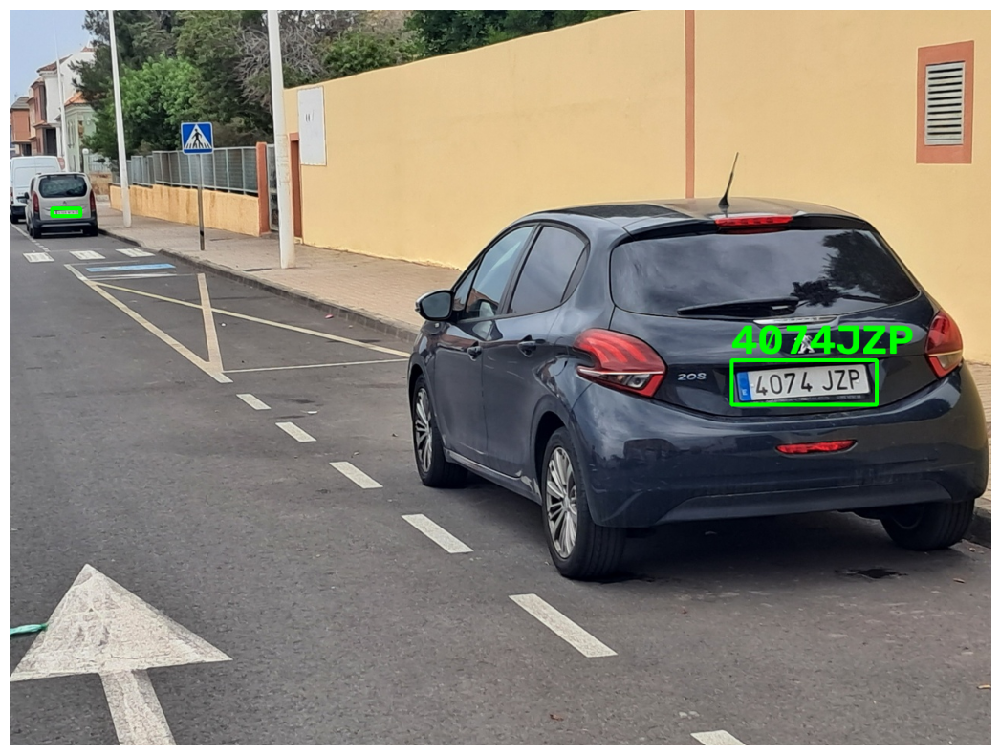

In [ ]:
extensiones = {".jpg", ".jpeg", ".png", ".bmp"}
imagenes = [p for p in TEST_IMG_DIR.iterdir() if p.is_file() and p.suffix.lower() in extensiones]
image = cv2.imread(str(random.choice(imagenes)))

# 1) RT-DETR detecta las matrículas  2) se recortan con margen  3) Florence-2 las lee
boxes, scores, _ = detect(model_mat, postprocessor_mat, image, size=800, conf=0.5)
crops = [crop_plate_v2(image, b) for b in boxes]
lecturas = [read_plates_v2([c], ocr_model, ocr_processor)[0] if c is not None else ("", "", None) for c in crops]

vis = image.copy()
lw = max(2, round(max(vis.shape[:2]) / 400))
for (x1, y1, x2, y2), s, (crudo, texto, conf) in zip(boxes.astype(int), scores, lecturas):
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), lw)
    cv2.putText(vis, texto, (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * lw, (0, 255, 0), lw)
    print(f"{texto or '(descartada)':<12} crudo {crudo!r:<20} conf OCR {conf or 0:.2f} | score detección {s:.2f}")

plt.figure(figsize=(15, 10)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.axis("off")

### 6.1.3 Elección del recorte y evaluación del OCR base

Se recorta cada matrícula legible de formato actual con su **caja real** (sin detector, para medir solo el OCR).
Además de *exact match* se mide:

- **aceptadas**: lecturas que dan una matrícula válida (las demás se descartan y no votan en vídeo);
- **precisión de las aceptadas**: de las que se aceptan, cuántas son correctas. Es lo que importa en vídeo, porque las descartadas no hacen daño.

El margen y la forma de preparar el recorte se eligen en **val**; **test** solo se usa al final con la configuración elegida.
Los valores definitivos están en `utils.py` (`MARGEN`, `PREP_MODE`) y son los que usan por defecto las Fases 7 y 8:
si esta celda recomienda otros, hay que cambiarlos allí.

In [ ]:
# Se prueban 3 márgenes x 2 preparaciones con Florence-2 base sobre val (caja real) y se elige la de mayor
# exact match. Test se usa una sola vez, después, con la configuración elegida: no influye en la elección.
muestras_val  = recoger("val", **DATOS_OCR)
muestras_test = recoger("test", **DATOS_OCR)
print(f"Matrículas legibles de formato actual: val {len(muestras_val)} | test {len(muestras_test)}\n")

resultados_cfg = {}
for margen in (0.08, 0.15, 0.25):
    for modo in ("pad", "estirar"):
        filas = eval_ocr_v2(muestras_val, ocr_model, ocr_processor, margen, modo)
        resultados_cfg[(margen, modo)] = resumen(filas, f"VAL · margen {margen:.2f} · {modo}")

margen_best, modo_best = max(resultados_cfg, key=resultados_cfg.get)
print(f"\nMejor en val: margen = {margen_best}, preparación = '{modo_best}'"
      f"  |  utils.py: MARGEN = {MARGEN}, PREP_MODE = '{PREP_MODE}'")
if (margen_best, modo_best) != (MARGEN, PREP_MODE):
    print("-> No coincide con utils.py: actualiza allí MARGEN y PREP_MODE para que las Fases 7 y 8 usen este recorte"
          " (y vuelve a entrenar la Fase 7, que recorta con MARGEN).")

# Evaluación final en test con la configuración elegida
filas_test = eval_ocr_v2(muestras_test, ocr_model, ocr_processor, margen_best, modo_best)
print()
resumen(filas_test, "TEST · configuración elegida")
por_alto(filas_test)
for orig in (True, False):                     # ¿cuánto aporta recortar de la foto original?
    g = [f for f in filas_test if f["original"] == orig]
    if g: resumen(g, "foto original" if orig else "solo 1280 px (sin original)")

print("\nErrores en test (real -> crudo -> extraído):")
for f in [f for f in filas_test if f["gt"] != f["pred"]][:15]:
    print(f"  {f['gt']:<8} -> {f['crudo'][:18]:<18} -> {f['pred'] or '(descartada)':<12} alto {f['alto']:.0f}px")

val: 372 recortes desde caché (0 de fotos originales)
test: 672 recortes desde caché (0 de fotos originales)
Matrículas legibles de formato actual: val 372 | test 672

VAL · margen 0.08 · pad      exact  58.3 % | aceptadas  73.7 % | precisión aceptadas  79.2 %
VAL · margen 0.08 · estirar  exact  54.8 % | aceptadas  70.2 % | precisión aceptadas  78.2 %
VAL · margen 0.15 · pad      exact  59.1 % | aceptadas  75.0 % | precisión aceptadas  78.9 %
VAL · margen 0.15 · estirar  exact  55.9 % | aceptadas  72.8 % | precisión aceptadas  76.8 %
VAL · margen 0.25 · pad      exact  59.9 % | aceptadas  76.3 % | precisión aceptadas  78.5 %
VAL · margen 0.25 · estirar  exact  56.5 % | aceptadas  73.1 % | precisión aceptadas  77.2 %

Mejor en val: margen = 0.25, preparación = 'pad'  |  utils.py: MARGEN = 0.25, PREP_MODE = 'pad'

TEST · configuración elegida exact  53.6 % | aceptadas  68.6 % | precisión aceptadas  78.1 %

 alto (px) |    n |   exact |  precisión aceptadas
      0-10 |  120 |   6.7 % |  

## 2. EasyOCR para la lectura de matrículas

- Implementación ligera basada en la librería easyocr (easyocr.Reader(['en'], gpu=True)), sin necesidad de descargar pesos pesados de modelos fundacionales.

- Requiere easyocr y PyTorch: pip install -U easyocr.

- El lector se instancia como ocr_reader para mantener la separación respecto a los modelos de detección (model_base, model_mat).

In [ ]:
import re, difflib
import cv2
import numpy as np
import torch
from PIL import Image
import easyocr
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Configurar si EasyOCR usará GPU basándose en el DEVICE existente
use_gpu = DEVICE.type == "cuda"
print(f"Dispositivo detectado para EasyOCR: {'GPU' if use_gpu else 'CPU'}")

# Inicializar el lector de EasyOCR para español
print("Cargando modelo EasyOCR...")
reader = easyocr.Reader(['es'], gpu=use_gpu)

print("EasyOCR cargado exitosamente.")

Dispositivo detectado para EasyOCR: GPU
Cargando modelo EasyOCR...
EasyOCR cargado exitosamente.


In [ ]:
# 1. Inicialización de EasyOCR (en lugar de Florence-2)
# languages=['en'] suele ser suficiente para matrículas (números y letras latinas)
# gpu=True usa aceleración por hardware si está disponible
ocr_reader = easyocr.Reader(['en'], gpu=True)

# El detector de matrículas se mantiene igual
model_easyOCR, postprocessor_easyOCR, _ = cargar_detector_matriculas(CFG_MAT, BEST_MAT, DEVICE)
print(f"EasyOCR inicializado (GPU: {use_gpu})")

def extraer_matricula(texto_crudo):
    """
    Limpia el texto leído por el OCR (eliminando la 'E' de la franja azul, 
    marcas como FLEXICAR, ruido) y valida el formato estándar (4 dígitos + 3 letras).
    """
    if not texto_crudo:
        return None
        
    texto = texto_crudo.upper()
    
    ruido = ["FLEXICAR", "ESPAÑA", "RANILES"]
    for palabra in ruido:
        texto = texto.replace(palabra, "")
    
    texto = re.sub(r'^E(?=\d)', '', texto)
    texto_limpio = re.sub(r'[^A-Z0-9]', '', texto)
    match = re.search(r'(\d{4})([BCDFGHJKLMNPRSTVWXYZ]{3})', texto_limpio)
    
    if match:
        numeros, letras = match.groups()
        return f"{numeros} {letras}"
        
    return None

# 2. Comprobación rápida de la extracción del formato con lecturas reales que fallaban
casos_prueba = ["E1685MBY", "19908KFK", "E4774JFWFLEXICAR", "IS172JYF", "6000KK", "RANILES", "7653LOS"]

for t in casos_prueba:
    print(f"{t:<18} -> {extraer_matricula(t) or '(descartada)'}")

EasyOCR inicializado (GPU: True)
E1685MBY           -> 1685 MBY
19908KFK           -> 9908 KFK
E4774JFWFLEXICAR   -> 4774 JFW
IS172JYF           -> (descartada)
6000KK             -> (descartada)
RANILES            -> (descartada)
7653LOS            -> (descartada)


### 7.2.1 Prueba con una imagen de test (detector + easyOCR)

8307 MGF     crudo '8307 MGF'           conf OCR 1.00 | score detección 0.86


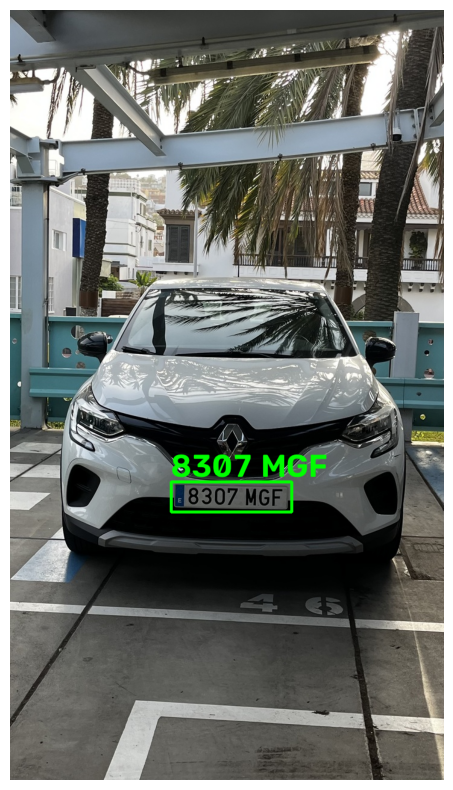

In [ ]:
# 0. Seleccionar imagen aleatoria de test
extensiones = {".jpg", ".jpeg", ".png", ".bmp"}
imagenes = [p for p in TEST_IMG_DIR.iterdir() if p.is_file() and p.suffix.lower() in extensiones]
image = cv2.imread(str(random.choice(imagenes)))

# 1) RT-DETR detecta las matrículas  2) se recortan con margen
boxes, scores, _ = detect(model_mat, postprocessor_mat, image, size=800, conf=0.5)
crops = [crop_plate_v2(image, b) for b in boxes]

# 3) Lectura y procesamiento con EasyOCR
lecturas = []
for c in crops:
    if c is not None and c.size > 0:
        gris = cv2.cvtColor(c, cv2.COLOR_BGR2GRAY)
        
        resultados_ocr = ocr_reader.readtext(gris)
        
        if resultados_ocr:
            crudo_unido = " ".join([res[1] for res in resultados_ocr])
            texto_formateado = extraer_matricula(crudo_unido)
            conf_media = sum(res[2] for res in resultados_ocr) / len(resultados_ocr)
            
            lecturas.append((crudo_unido, texto_formateado, conf_media))
        else:
            lecturas.append(("", None, 0.0))
    else:
        lecturas.append(("", None, 0.0))

# 4) Visualización de resultados
vis = image.copy()
lw = max(2, round(max(vis.shape[:2]) / 400))

for (x1, y1, x2, y2), s, (crudo, texto, conf) in zip(boxes.astype(int), scores, lecturas):
    texto_a_mostrar = crudo if crudo else "(ilegible)"
    cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), lw)
    cv2.putText(vis, texto_a_mostrar, (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * lw, (0, 255, 0), lw)
    print(f"{texto_a_mostrar:<12} crudo {crudo!r:<20} conf OCR {conf or 0:.2f} | score detección {s:.2f}")

plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
def eval_easyocr(muestras, margen, modo):
    filas = []

    for m in muestras:
        crop = utils.crop_plate_v2(m["ctx"], m["box"], margen)
        if crop is None:
            continue

        # Aplica la misma preparación pad/estirar que se prueba con Florence-2.
        imagen_rgb = np.asarray(utils.preparar(crop, modo))
        lecturas = ocr_reader.readtext(
            imagen_rgb,
            detail=1,
            paragraph=False,
            allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789",
        )
        lecturas.sort(key=lambda r: min(p[0] for p in r[0]))

        crudo = "".join(texto for _, texto, _ in lecturas)
        pred = utils.extraer_matricula(crudo)
        conf = float(np.mean([c for _, _, c in lecturas])) if lecturas else None

        filas.append({
            "file": m["file"],
            "gt": m["text"],
            "alto": m["alto"],
            "alto_px": m["alto_px"],
            "original": m["original"],
            "crudo": crudo,
            "pred": pred,
            "conf": conf,
        })

    return filas

In [ ]:
muestras_val = recoger("val", **DATOS_OCR)
muestras_test = recoger("test", **DATOS_OCR)
print(f"Matrículas legibles: val {len(muestras_val)} | test {len(muestras_test)}\n")

resultados_cfg = {}
for margen in (0.08, 0.15, 0.25):
    for modo in ("pad", "estirar"):
        filas = eval_easyocr(muestras_val, margen, modo)
        resultados_cfg[(margen, modo)] = resumen(
            filas, f"VAL · margen {margen:.2f} · {modo}"
        )

margen_best, modo_best = max(resultados_cfg, key=resultados_cfg.get)
print(f"\nMejor configuración EasyOCR en val: margen={margen_best}, preparación='{modo_best}'")

filas_test = eval_easyocr(muestras_test, margen_best, modo_best)
print()
resumen(filas_test, "TEST · EasyOCR")
por_alto(filas_test)

for orig in (True, False):
    g = [f for f in filas_test if f["original"] == orig]
    if g:
        resumen(g, "foto original" if orig else "solo 1280 px")

print("\nErrores en test (real -> crudo -> extraído):")
for f in [f for f in filas_test if f["gt"] != f["pred"]][:15]:
    print(
        f"  {f['gt']:<8} -> {f['crudo'][:18]:<18} -> "
        f"{f['pred'] or '(descartada)':<12} alto {f['alto']:.0f}px"
    )

val: 372 recortes desde caché (0 de fotos originales)
test: 672 recortes desde caché (0 de fotos originales)
Matrículas legibles: val 372 | test 672

VAL · margen 0.08 · pad      exact  30.1 % | aceptadas  48.4 % | precisión aceptadas  62.2 %
VAL · margen 0.08 · estirar  exact  22.6 % | aceptadas  47.8 % | precisión aceptadas  47.2 %
VAL · margen 0.15 · pad      exact  29.8 % | aceptadas  48.4 % | precisión aceptadas  61.7 %
VAL · margen 0.15 · estirar  exact  23.1 % | aceptadas  46.5 % | precisión aceptadas  49.7 %
VAL · margen 0.25 · pad      exact  30.9 % | aceptadas  48.9 % | precisión aceptadas  63.2 %
VAL · margen 0.25 · estirar  exact  22.8 % | aceptadas  46.8 % | precisión aceptadas  48.9 %

Mejor configuración EasyOCR en val: margen=0.25, preparación='pad'

TEST · EasyOCR               exact  25.0 % | aceptadas  40.2 % | precisión aceptadas  62.2 %

 alto (px) |    n |   exact |  precisión aceptadas
      0-10 |  120 |   0.0 % |                0.0 %
     10-14 |  113 |   1.8 %

## 3. Comparación de resultados entre Florence 2 base y EasyOCR

En la siguiente tabla se resumen los resultados obtenidos tras las ejecuciones de los apartados 6.1.3 y 6.2.3

| **Modelo** |   Florence-2   |   EasyOCR   |
| :--- | :---: | :---: |
| **Tiempo de ejecución** | | |
| Minutos | 54 minutos| 4 minutos |
| Segundos | 40 segundos | 52 segundos |
| **Configuraciones de recorte** |
| Mejor margen | 0.25 | 0.25 |
| Mejor preparación | pad | pad |
| **Tasa de aciertos en VAL** |
| Exactas | 53.6% | 25.0% |
| Aceptadas | 68.6% | 40.2% |
| Precisión aceptadas | 78.1% | 62.2% |
| **Aciertos exactos con distintos tamaños (px de alto)** |
| 0-10 px | 6.7% | 0.0% |
| 10-14 px | 29.2% | 1.8% |
| 14-18 px | 44.0% | 16.0% |
| 18-24 px | 56.3% | 19.5% |
| 24-32 px | 82.7% | 34.7% |
| >32 px | 86.6% | 55.0% |

- **Tiempo de ejecución:** Podemos observar que Florence 2, en comparación, ha tardado 50 minutos más en validarse con las imagenes de test y de val que easyOCR, esto se debe principalmente a que es un modelo mucho más grande con un coste computacional mucho mayor que easyOCR, siendo este útlimo mucho más ligero.

- **Configuraciones de recorte:** En este punto los dos modelos obtienen sus mejores resultados usando un margen de 0.25 y el modo de preparación "pad". Esto se debe a que al dejar un margen más amplio en torno a la matrícula detectada hace más fácil a un OCR leer correctamente el texto. A su vez es más eficiente ajustar las imagenes añadiendo un relleno que mantiene las proporciones originales de la matricula frente (modo padding) a estirar la imagen artificialmente deformando el texto (modo estirar).

- **Tasa de aciertos en VAL:** Florence 2 presenta una tasa de lectura exacta del 53.6% de las matriculas, frente al 25% de easyOCR. Por otro lado Florence 2 también acepta más matrículas que easyOCR y obtiene una mayor precisión que en las aceptadas que easyOCR (acierta el 78.1% de las acertadas frente al 62.2% de easyOCR). Podemos concluir que Florence 2 es bastante más robusto.

- **Rendimiento según el tamaño de la matrícula:** Vemos que los dos modelos tienen exactamente la misma tendencia, con resoluciones muy bajas aciertan muy poco en comparación a resoluciones más altas. En el mejor caso para ambos (matriculas de más de 32px de alto) Florence 2 acierta el 86.6% de las matrículas mientras que easyOCR acierta el 55%. Lo interesante en este punto es la tendencia que siguen ambos modelos, que es muy similar.

### Conclusiones (Florence 2 base vs EasyOCR)

Podemos concluir que Florence 2 base es un modelo mucho más preciso y robusto en la lectura de matrículas del dataset disponible, pero es cierto que es muchisimo más pesado y complejo, hasta el punto de tardar 50 minutos más que EasyOCR en validarse en el conjunto de datos